# Blue Straggler Analysis Pipeline


## Prerequisites:
### Packages needed
Add these with 'pip install'

- hdbscan
- shapely

### Files needed
These should be included in the .zip download

- getGaiaData.py
- read_mist_models.py
- PARSEC.model
- Hunt2023.tsv

# 1. Initial Setup

## Input required:
Prior Cluster information: 
- Input name, age, distance, extinction, metallicity below
- Find these from the Hunt 2023 catalog or other literature

MIST isochrone:
- Download interpolated isochrone from https://mist.science/interp_isos.html
- Use your cluster age and metallicity
- Choose synthetic photometry option: "UBV(RI)c + 2MASS + Kepler + Hipparcos + Gaia + Tess"
- Put this file in the "cluster/isochrones" folder and specify the filename below

In [215]:
### cluster name
cluster_name = "NGC_2243"

### log age
age= 9.56 

### distance modulus
dmod = 13.0
err_dmod = 1.0

### extinction
Av = 0.161
err_Av = 0.1

### metallicity
FeH = -0.32
err_FeH = 0.1

isochrone_filename = 'MIST_iso_69d2b4facbd58.iso.UBVRIplus'

print("Cluster Name: \n" + cluster_name + "\n")
print("Cluster Log Age \n = " + str(age) + "\n")
print("Cluster Distance Modulus \n = " + str(dmod) + " +/- " + str(err_dmod) + "\n")
print("Cluster Extinction \n = " + str(Av) + " +/- " + str(err_Av) + "\n")
print("Cluster Metallicity \n = " + str(FeH) + " +/- " + str(err_FeH))

Cluster Name: 
NGC_2243

Cluster Log Age 
 = 9.56

Cluster Distance Modulus 
 = 13.0 +/- 1.0

Cluster Extinction 
 = 0.161 +/- 0.1

Cluster Metallicity 
 = -0.32 +/- 0.1


## Internal Setup

### No input required

In [216]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hdbscan
import read_mist_models
import astropy.units as units

from scipy.interpolate import interp1d
from astropy.coordinates import SkyCoord
from astropy.table import Table
from bokeh.plotting import *
from getGaiaData import GaiaClusterMembers

output_notebook()
%load_ext autoreload
%autoreload 2


os.makedirs("clusters/" + cluster_name, exist_ok = True)
cluster_path = "clusters/" + cluster_name + "/"
plot_path = cluster_path + "plots/"

# create folders in cluster directory
os.makedirs(cluster_path + "isochrones", exist_ok = True)

# create folders in cluster/plot directory
os.makedirs(plot_path + "ages", exist_ok = True)
os.makedirs(plot_path + "cmd", exist_ok = True)
os.makedirs(plot_path + "masses", exist_ok = True)
os.makedirs(plot_path + "plots", exist_ok = True)
os.makedirs(plot_path + "relative_ages", exist_ok = True)
os.makedirs(plot_path + "transformation_beta_contours", exist_ok = True)
os.makedirs(plot_path + "transformation_Macc_contours", exist_ok = True)

### load in cluster photometry
cluster_df = pd.read_csv(cluster_name + ".phot",delimiter=' ',dtype={'id': str})
cluster_ids = cluster_df['id']
cluster_G = cluster_df['G']
cluster_bp = cluster_df['G_BP']
cluster_rp = cluster_df['G_RP']
cluster_bp_rp = cluster_bp-cluster_rp

isocmd = read_mist_models.ISOCMD(cluster_path + 'isochrones/' + isochrone_filename)
age_ind= isocmd.age_index(age)
w= np.where(isocmd.isocmds[age_ind]['phase']<6.0)
ebprp= Av/2.394
g_iso= isocmd.isocmds[age_ind]['Gaia_G_DR2Rev'][w] + dmod
bp_iso= isocmd.isocmds[age_ind]['Gaia_BP_DR2Rev']
rp_iso= isocmd.isocmds[age_ind]['Gaia_RP_DR2Rev']
iso_bprp = isocmd.isocmds[age_ind]['Gaia_BP_DR2Rev'][w] - isocmd.isocmds[age_ind]['Gaia_RP_DR2Rev'][w]

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Loading BokehJS ...

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Reading in: clusters/NGC_2243/isochrones/MIST_iso_69d2b4facbd58.iso.UBVRIplus


In [217]:
### figure out better way to handle eeptrack filenames
# maybe use * to use all files in a folder like "*.track.eep.cmd"

tracks_folder = 'eep_tracks/'

tams_tracks = pd.DataFrame({
    "filename": [
        "0002000M.track.eep.cmd",
        "0003000M.track.eep.cmd",
        "0004000M.track.eep.cmd",
        "0005000M.track.eep.cmd",
        "0006000M.track.eep.cmd",
        "0007000M.track.eep.cmd",
        "0008000M.track.eep.cmd",
        "0009000M.track.eep.cmd",
        "0010000M.track.eep.cmd",
        "0011000M.track.eep.cmd",
        "0012000M.track.eep.cmd",
        "0013000M.track.eep.cmd",
        "0014000M.track.eep.cmd",
        "0015000M.track.eep.cmd",
        "0016000M.track.eep.cmd",
        "0017000M.track.eep.cmd",
        "0018000M.track.eep.cmd",
        "0019000M.track.eep.cmd",
        "0020000M.track.eep.cmd",
        "0021000M.track.eep.cmd",
        "0022000M.track.eep.cmd",
        "0023000M.track.eep.cmd",
        "0024000M.track.eep.cmd",
        "0025000M.track.eep.cmd",
        "0026000M.track.eep.cmd",
        "0027000M.track.eep.cmd",
        "0028000M.track.eep.cmd",
        "0029000M.track.eep.cmd",
        "0030000M.track.eep.cmd"
    ]
})

eep_tracks = pd.DataFrame({
    "track": [
        "0010000M.track.eep.cmd",
        "0012000M.track.eep.cmd",
        "0014000M.track.eep.cmd",
        "0016000M.track.eep.cmd",
        "0018000M.track.eep.cmd",
        "0020000M.track.eep.cmd",
        "0022000M.track.eep.cmd",
        "0024000M.track.eep.cmd",
        "0026000M.track.eep.cmd",
        "0028000M.track.eep.cmd",
        "0030000M.track.eep.cmd"
    ]
})

# 2. Cluster membership and generating photometry files
### Code Credit: Anna Childs

set query=True if you need to query the data from Gaia or generate the adql for an OC

In [220]:
Hunt = pd.read_csv('Hunt2023.tsv',sep='\s+', header=94)

def distance_modulus_to_pc(distance_modulus):
    return 10 ** ((distance_modulus + 5) / 5)

def run_pipeline(clusterName,query=False):
    cluster = GaiaClusterMembers()
    pwd = clusterName+'_dir' #change this pwd as needed
    if os.path.isdir(pwd):
        print("Directory exists.")
    else:
        os.makedirs(pwd)
        os.makedirs(pwd+'/plots')
    cluster.plotNameRoot = pwd+'/plots/'
    cluster.photOutputFileName = pwd +'/'+clusterName + '.phot'
    cluster.saveDataFile = pwd +'/'+clusterName + '.csv'
    cluster.yamlOutputFileName = pwd + '/base9.yaml'
    cluster.yamlTemplateFileName = 'template_base9.yaml'
    
    Hunt_data = Hunt[Hunt['Name']==clusterName]
    cluster.rt = Hunt_data['rt'].values[0]
    #Av = round(Hunt_data['AV50'].values[0],5)
    #err_Av = round(Hunt_data['AV84'].values[0],5)
    
    #logAge = round(Hunt_data['logAge50'].values[0],5)
    #dmod = round(Hunt_data['MOD50'].values[0],5)
    
    #err_dmod = round(Hunt_data['MOD50'].values[0]-Hunt_data['MOD16'].values[0],5)

    logAge = age

    start_dmod = dmod
    start_FeH = FeH
    start_Av = Av
    start_age = logAge
    cluster.yamlInputDict = {
        'photFile' : clusterName + '.phot',
        'outputFileBase' : clusterName,
        'modelDirectory' : '/Users/daisymatthews/base9/base-cpp-9.6.0/base-models/',
        'msRgbModel' : 5,
        'Fe_H' : [start_FeH, FeH, err_FeH, 0.3],
        'Av' : [start_Av, Av, err_Av, 0.3],
        'Y' : [0.29, 0.29, 0.0], # keep the defaults
        'carbonicity' : [0.38, 0.38, 0.0], # keep the defaults
        'logAge' : [start_age, logAge, np.inf],
        'distMod' : [start_dmod, dmod, err_dmod],
    }
    
    if query:
        cluster.radius = float(input("What radius to query from Gaia? (Deg)"))
        cluster.query_data(clusterName,pwd+'/'+clusterName+'_GaiaData.ecsv') #run this line to download Gaia data that will be saved to the file clusterName+'_dir/'+clusterName+'_GaiaData.ecsv'
    else:
        prior_pc = distance_modulus_to_pc(dmod)
        print ("Prior distance = ",prior_pc," pc") #I show this as a check that I am looking at the right OC
        cluster.runAll(clusterName,filename= clusterName+'_dir/'+clusterName+'_GaiaData.ecsv') #run this line if Gaia data has already been downloaded  
        cluster.photOutputFileName = pwd+'/'+ clusterName + '_sig1.phot'
        return cluster
cluster = run_pipeline('NGC_2243', query=True)

Directory exists.


What radius to query from Gaia? (Deg) 


ValueError: could not convert string to float: ''

# 3. Color-Magnitude Diagram and Target Selection

## Input required:

### CMD box selection for BSS and YSS

Set upper and lower bounds in color and magnitude to make selections

Standard for BSS currently with color left of blue hook

In [223]:
bss_bp_rp_lower = 0
bss_bp_rp_upper = 0.6
bss_G_lower = 0
bss_G_upper = 17

yss_bp_rp_lower = 0.9
yss_bp_rp_upper = 1.0
yss_G_lower = 13.5
yss_G_upper = 15.5

### Single Gaia ID search selection

Use this to add individual targets that were missed by the box selection

In [224]:
single_search_name = "2893941821518204544"

### Select region to estimate CMD color error

We want to show approximate error bars to assess how much our cluster members deviate from the isochrone

Select a well-behaved segment of the main-sequence

In [225]:
error_bp_rp_lower = 0.5
error_bp_rp_upper = 1.2
error_G_lower = 16.5
error_G_upper = 18

## No input required below here

Reading in: clusters/NGC_2243/isochrones/MIST_v1.2_feh_m0.25_afe_p0.0_vvcrit0.0_UBVRIplus.iso.cmd
All candidates:


,id,G,G_BP,G_RP,g_ps,r_ps,i_ps,z_ps,y_ps,J_2M,...,sigy_ps,sigJ_2M,sigH_2M,sigKs_2M,mass1,massRatio,stage1,CMprior,useDBI,type
240,2893941099963718528,15.0932,15.1855,14.9340,15.324,15.1951,15.2896,15.4460,15.4960,14.780,...,-9.9000,0.041,0.060,0.079,1.1,0.0,1.0,0.900,1.0,bss
346,2893941890237671936,15.1026,15.1577,15.0126,15.277,15.2128,15.3599,15.4460,15.5760,14.870,...,-9.9000,0.049,0.073,0.136,1.1,0.0,1.0,0.900,1.0,bss
416,2893942062036322688,15.3216,15.5455,14.9556,17.093,15.3556,15.3058,15.8450,15.7440,14.689,...,-9.9000,0.037,0.047,0.078,1.1,0.0,1.0,0.791,1.0,bss
559,2893942714871393280,16.4971,16.7112,16.1437,17.201,16.5323,16.4875,16.6900,16.6770,15.789,...,-9.9000,0.085,0.095,0.206,1.1,0.0,1.0,0.142,1.0,bss
577,2893942749231117568,14.1981,14.2240,14.1541,13.670,14.3445,14.5196,14.4530,14.6120,14.090,...,-9.9000,0.026,0.023,0.063,1.1,0.0,1.0,0.900,1.0,bss
590,2893942783590846080,15.2893,15.3476,15.1939,14.635,15.4055,15.5473,16.1590,15.5640,15.020,...,-9.9000,0.051,-9.900,-9.900,1.1,0.0,1.0,0.754,1.0,bss
788,2893946150845192192,15.3370,15.5567,14.9787,15.343,15.3449,15.3423,15.3170,15.3140,14.560,...,-9.9000,0.029,0.040,0.085,1.1,0.0,1.0,0.383,1.0,bss
801,2893946563162115712,15.9810,16.1709,15.6677,16.009,16.0124,16.0111,16.0520,16.0990,15.339,...,-9.9000,0.054,0.073,0.205,1.1,0.0,1.0,0.453,1.0,bss
840,2893948212429455360,16.2184,16.3991,15.9250,16.381,16.2655,16.2653,16.3033,16.2854,15.637,...,0.0326,0.059,0.091,0.173,1.1,0.0,1.0,0.900,1.0,bss
417,2893942062036323200,15.1180,15.5253,14.5410,20.922,15.1131,14.9077,16.2530,15.8640,13.819,...,-9.9000,0.023,0.027,0.042,1.1,0.0,1.0,0.900,1.0,yss


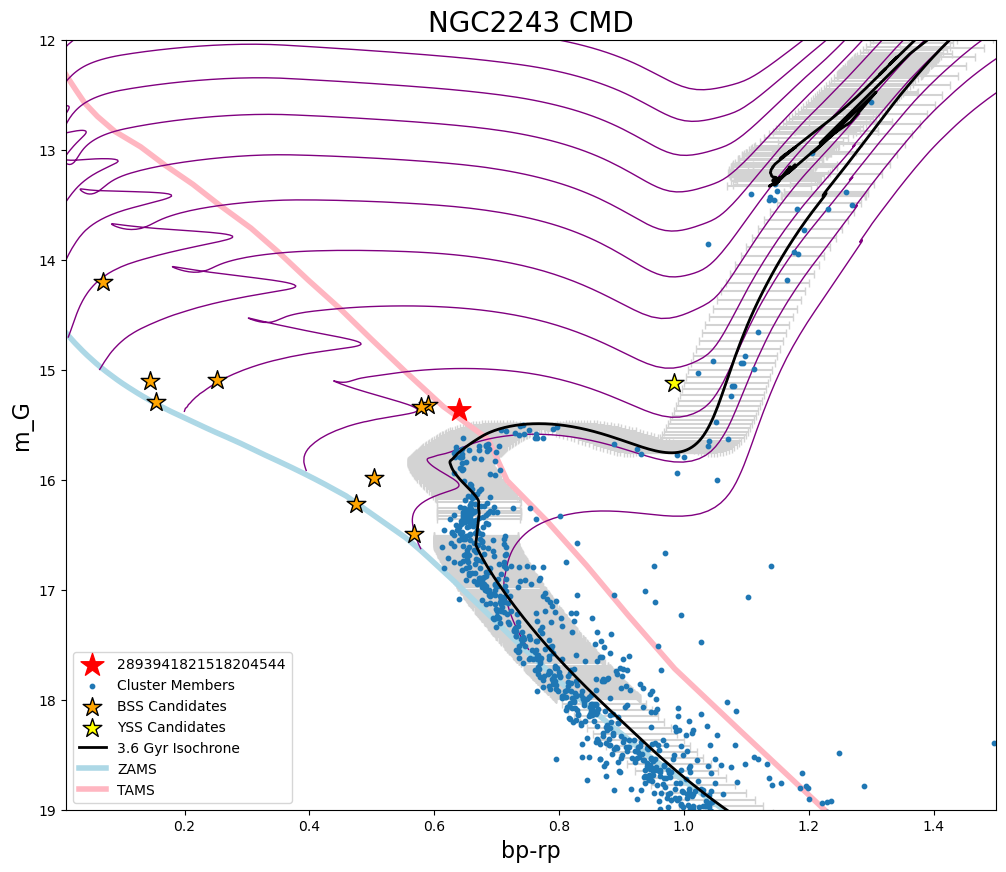

In [118]:

# single search

single_search = cluster_df.where(cluster_ids==single_search_name).dropna()
single_search['type'] = 'bss'
single_search_id = single_search['id']
single_search_G = single_search['G']
single_search_bprp = single_search['G_BP'] - single_search['G_RP']
plt.scatter(single_search_bprp,single_search_G,color='red',label=single_search_name,s=300,marker='*',zorder=10)


# box search

bss_cut = cluster_df.where(((cluster_bp_rp < bss_bp_rp_upper) & (cluster_bp_rp > bss_bp_rp_lower) & (cluster_G < bss_G_upper) & (cluster_G > bss_G_lower))).dropna()
bss_cut['type'] = 'bss'
bss_ids = bss_cut['id']
bss_G = bss_cut['G']
bss_bp = bss_cut['G_BP']
bss_rp = bss_cut['G_RP']
bss_bp_rp = bss_bp - bss_rp

yss_cut = cluster_df.where(((cluster_bp_rp < yss_bp_rp_upper) & (bp_rp > yss_bp_rp_lower) & (cluster_G < yss_G_upper) & (cluster_G > yss_G_lower))).dropna()
yss_cut['type'] = 'yss'
yss_ids = yss_cut['id']
yss_G = yss_cut['G']
yss_bp = yss_cut['G_BP']
yss_rp = yss_cut['G_RP']
yss_bp_rp = yss_bp - yss_rp

# make folders for all candidates
all_candidates = pd.concat([bss_cut, yss_cut,single_search], ignore_index=False)
all_ids = all_candidates['id']

for ids in all_ids:
    os.makedirs(cluster_path + 'stars/' + ids, exist_ok=True)
    

#bss_final_list.append(single_search)

### calculate standard deviation of cluster members from user-selected isochrone segment

res_mem = cluster_df.where(((cluster_bp_rp < error_bp_rp_upper) & (cluster_bp_rp > error_bp_rp_lower) & (cluster_G < error_G_upper) & (cluster_G > error_G_lower))).dropna()

iso_bprp_final = iso_bprp+ebprp
df_iso = pd.DataFrame({"g_iso": g_iso, "bprp": iso_bprp_final})
res_iso = df_iso.where(((df_iso['bprp'] < error_bp_rp_upper) & (df_iso['bprp'] > error_bp_rp_lower) & (df_iso['g_iso'] < error_G_upper) & (df_iso['g_iso'] > error_G_lower))).dropna()

res_mem_sorted = res_mem.sort_values(by='G')
res_iso_reverse = res_iso.iloc[::-1]

iso_interp = np.interp(res_mem_sorted['G'],res_iso_reverse['g_iso'],res_iso_reverse['bprp'])
bprp_residual = iso_interp - (res_mem_sorted['G_BP'] - res_mem_sorted['G_RP'])
bprp_stdev = np.std(bprp_residual,ddof=1)

# plot cluster members

plt.scatter(cluster_bp_rp,cluster_G,label='Cluster Members',s=10)

# plot candidates 

plt.scatter(bss_bp_rp,bss_G,color='orange',label='BSS Candidates',s=200,marker='*',edgecolors='black')
plt.scatter(yss_bp_rp,yss_G,color='yellow',label='YSS Candidates',s=200,marker='*',edgecolors='black')

# plot isochrone

plt.plot(iso_bprp_final, g_iso, '-', color= 'black', lw= 2, label= str(np.round(10**age/1e9, 1))+' Gyr Isochrone',zorder=10)

plt.errorbar(iso_bprp_final,g_iso, xerr=bprp_stdev, color='lightgray',zorder=-40,capsize=3)
plt.errorbar(iso_interp,res_mem_sorted['G'], xerr=bprp_stdev, color='lightgray',zorder=-40,capsize=3)


### ZAMS ###

# note: this is with fe/h=-0.25, should redo this interpolated at fe/h=-0.32

zams_isochrone_filename = 'MIST_v1.2_feh_m0.25_afe_p0.0_vvcrit0.0_UBVRIplus.iso.cmd'
zams_isocmd = read_mist_models.ISOCMD(cluster_path + "isochrones/" + zams_isochrone_filename)

zams_age_ind= zams_isocmd.age_index(8)
zams_w= np.where(zams_isocmd.isocmds[zams_age_ind]['phase']<6.0)

zams_ebprp= Av/2.394

zams_g = zams_isocmd.isocmds[zams_age_ind]['Gaia_G_DR2Rev'][zams_w] + dmod
zams_bprp = zams_isocmd.isocmds[zams_age_ind]['Gaia_BP_DR2Rev'][zams_w] - zams_isocmd.isocmds[zams_age_ind]['Gaia_RP_DR2Rev'][zams_w]+zams_ebprp

plt.plot(zams_bprp, zams_g, '-', color= 'lightblue', lw= 4, label= "ZAMS",zorder=-10)

### TAMS ###

tams_g = []
tams_bprp = []

for filenames in tams_tracks['filename']:
    tams_load = read_mist_models.EEPCMD(cluster_path + tracks_folder + filenames,verbose=False)
    
    tams_data = tams_load.eepcmds[tams_load.eepcmds['phase'] == 2]
    
    tams_g_load = tams_data['Gaia_G_DR2Rev']
    tams_bp_load = tams_data['Gaia_BP_DR2Rev']
    tams_rp_load = tams_data['Gaia_RP_DR2Rev']
    tams_ebprp= Av/2.394

    tams_g.append(tams_g_load[0]+dmod)
    tams_bprp.append(tams_bp_load[0]-tams_rp_load[0]+tams_ebprp)

plt.plot(tams_bprp, tams_g, '-', color='lightpink', lw= 4, label= "TAMS",zorder=-10)

# load and plot EEP tracks
for tracks in eep_tracks['track']:
    tracks_load = read_mist_models.EEPCMD(cluster_path + tracks_folder + tracks,verbose=False)

    tracks_data = tracks_load.eepcmds[(tracks_load.eepcmds['phase'] < 3)]

    tracks_g_load = tracks_data['Gaia_G_DR2Rev']
    tracks_bp_load = tracks_data['Gaia_BP_DR2Rev']
    tracks_rp_load = tracks_data['Gaia_RP_DR2Rev']
    tracks_ebprp= Av/2.394

    tracks_g = tracks_g_load + dmod
    tracks_bprp = tracks_bp_load - tracks_rp_load + tracks_ebprp

    upper_cut = 1
    tracks_g_upper = tracks_g[:upper_cut]
    tracks_bprp_upper = tracks_bprp[:upper_cut]

    final_cut = 300
    tracks_g_final = tracks_g[final_cut:]
    tracks_bprp_final = tracks_bprp[final_cut:]
    
    plt.plot(tracks_bprp_final, tracks_g_final, '-', color='purple', lw= 1,zorder=-10)

# 




### parameters for plot

plt.rcParams['figure.figsize'] = (12,10)
plt.ylim(19, 12)
plt.xlim(0.01, 1.5)
plt.xlabel('bp-rp',fontsize=16)
plt.ylabel('m_G',fontsize=16)
plt.title("NGC2243 CMD",fontsize=20)

#tams_interp = np.interp(zams_bprp, tams_bprp, tams_g)
#plt.fill_between(zams_bprp, tams_interp, zams_g, color="gray", alpha=0.3)

plt.legend()
plt.savefig(cluster_path + "plots/cmd/NGC2243_CMD.png")

print("All candidates:")
all_candidates

# 4. Create histograms and measure averages

In [120]:
os.makedirs(cluster_path + "plots/masses/", exist_ok=True)
os.makedirs(cluster_path + "plots/ages/", exist_ok=True)

all_masses = []

for ids in all_ids:
    df_bss_mass = pd.read_csv(cluster_path + "stars/" + ids + "/" + ids + ".sampleMass.out",sep=r'\s+',usecols=["mass"])
    df_bss_mass_drop = df_bss_mass[df_bss_mass.ne(0).all(axis=1)]
    all_masses.append(np.average(df_bss_mass_drop))
    plt.hist(df_bss_mass_drop);
    plt.xlabel("Mass (Msun)");
    plt.ylabel("N");
    plt.title("Masses for " + ids + " (N = " + str(len(df_bss_mass_drop)) + ")");
    plt.savefig(cluster_path + "plots/masses/mass_hist_" + ids + ".png");
    plt.clf();

all_ages = []

for ids in all_ids:
    df_bss_age = pd.read_csv(cluster_path + "stars/" + ids + "/" + ids + ".res",sep=r'\s+',usecols=["logAge"])
    all_ages.append(np.average(df_bss_age))
    plt.hist(df_bss_age);
    plt.xlabel("Log Age (Log Years)");
    plt.ylabel("N");
    plt.title("Ages for " + ids + " (N = " + str(len(df_bss_age)) + ")");
    plt.savefig(cluster_path + "plots/ages/age_hist_" + ids + ".png");
    plt.clf();

<Figure size 1200x1000 with 0 Axes>

# 5. Relative Age Plots
## Code Credit: Gabriela Escobedo
### No input required

Columns in PARSEC model:
['EEP', 'Mass', 'logL', 'logT', 'U', 'B', 'V', 'R', 'I', 'J', 'H', 'K', 'u', 'g', 'r', 'i', 'z', 'g_ps', 'r_ps', 'i_ps', 'z_ps', 'y_ps', 'w_ps', 'G', 'G_BP', 'G_RP', 'F435W', 'F475W', 'F555W', 'F606W', 'F625W', 'F775W', 'F814W', 'WFC218W', 'WFC225W', 'WFC275W', 'WFC336W', 'WFC390W', 'WFC438W', 'WFC475W', 'WFC555W', 'WFC606W', 'WFC625W', 'WFC775W', 'WFC814W', 'WFC105W', 'WFC110W', 'WFC125W', 'WFC140W', 'WFC160W', 'UK_Z', 'UK_Y', 'UK_J', 'UK_H', 'UK_K', 'J_2M', 'H_2M', 'Ks_2M', 'W1', 'W2', 'W3', 'W4', 'JW070W', 'JW090W', 'JW115W', 'JW150W', 'JW200W', 'JW277W', 'JW356W', 'JW444W', 'JW150W2', 'JW322W2', 'logAge', 'Fe_H']
   EEP      Mass   logL   logT       U       B       V      R      I      J  \
0  1.0  0.093634 -1.774  3.570  12.803  11.696  10.288  9.313  8.528  7.540   
1  2.0  0.095178 -1.765  3.571  12.762  11.663  10.260  9.288  8.505  7.520   
2  3.0  0.097651 -1.751  3.572  12.697  11.609  10.214  9.247  8.468  7.488   
3  4.0  0.101619 -1.728  3.574  12

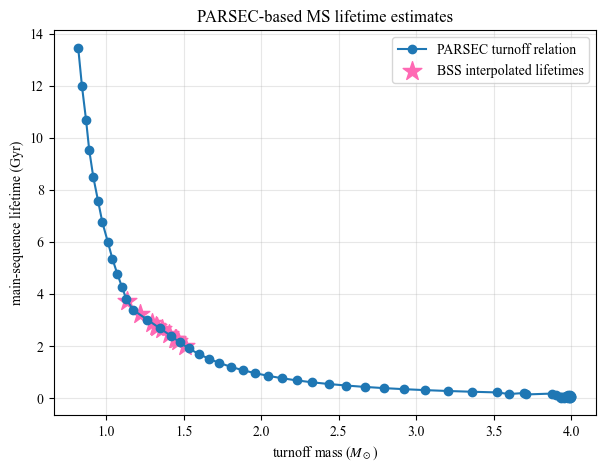

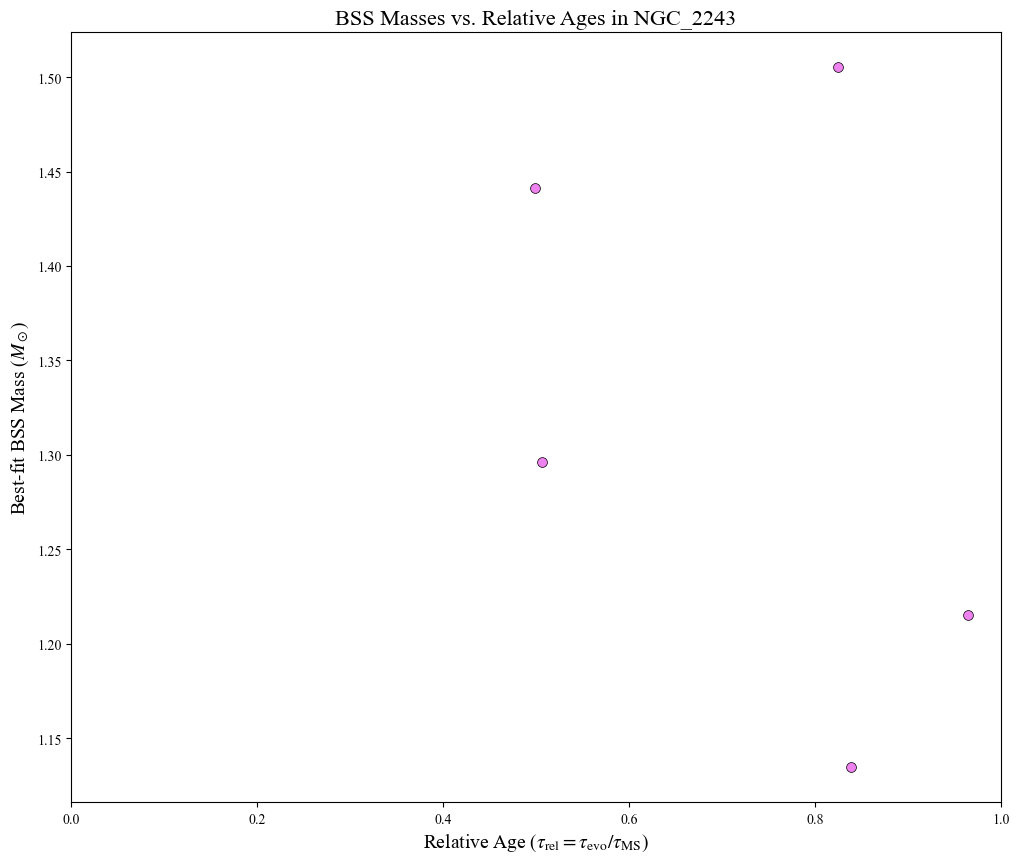

In [226]:
bss_data = pd.DataFrame({
    "Gaia Star ID": 
        all_ids
    ,
    "Mean Mass": 
        all_masses
    ,
    "log Age BASE9": 
        all_ages
    
})

# 2. reading the BASE-9 PARSEC model file
    # this file contains steller evolution model points, and BASE-9 uses the model grids to compare observed stars with theoretical stars.
    # PARSEC file is organized into different blocks:
        # lines beginning with "%s":identify metallicity, Fe/H
        # lines beginning with "%a": identify age, logAge
        # lines beginning with "# EEP": give column names
        # other rows give the actual model data for one point along an isochrone
    # function also reads the file and turns it into a DataFrame, then adds the current logAge & Fe/H to every model row
        # does this so that each row is labeled with the age and metallicty of the isochrone it came from!

def read_base9_parsec_model(model_file="PARSEC.model"):
    rows = []
    columns = None
    current_feh = None
    current_logage = None

    with open(model_file, "r") as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            # metallicity block
            if line.startswith("%s"):
                parts = line.replace("=", " ").split()
                current_feh = float(parts[2])

            # age block
            elif line.startswith("%a"):
                parts = line.replace("=", " ").split()
                current_logage = float(parts[2])

            # column header
            elif line.startswith("# EEP"):
                columns = line.replace("#", "").split()
                columns += ["logAge", "Fe_H"]

            # data row
            elif columns is not None and not line.startswith("#") and not line.startswith("%"):
                vals = line.split()
                if len(vals) == len(columns) - 2:
                    vals += [current_logage, current_feh]
                    rows.append(vals)

    df = pd.DataFrame(rows, columns=columns).astype(float)
    return df

parsec = read_base9_parsec_model("PARSEC.model")

# read in the PARSEC model grid (make sure PARSEC.model is in the same folder as code)
print("Columns in PARSEC model:")
print(parsec.columns.tolist())
print(parsec.head())

# 3. identifying useful columns
    # different stellar model files can use slightly different column names :-(
        # cell here finds the columnn with the stellar mass and Gaia filters. in the PARSEC.model file, these are:
            # mass_col = "Mass"; G_col = "G"; BP_col = "G_BP"; and RP_col = "G_RP"
        

#possible mass-column names in different PARSEC/BASE-9 formats
mass_candidates = [
    "mass", "Mass", "MASS", "M_ini", "Mini", "initial_mass",
    "Mact", "M_current", "M"
]

mass_col = None
for c in mass_candidates:
    if c in parsec.columns:
        mass_col = c
        break

if mass_col is None:
    raise ValueError(
        "Could not automatically identify the mass column. "
        "Look at the printed column list and manually set mass_col."
    )

#Gaia filter names after BASE-9 formatting are usually G, G_BP, G_RP, but some files use other names (like phot_g_mean_mag).
possible_G = ["G", "phot_g_mean_mag"]
possible_BP = ["G_BP", "phot_bp_mean_mag"]
possible_RP = ["G_RP", "phot_rp_mean_mag"]

G_col = next((c for c in possible_G if c in parsec.columns), None)
BP_col = next((c for c in possible_BP if c in parsec.columns), None)
RP_col = next((c for c in possible_RP if c in parsec.columns), None)

if G_col is None or BP_col is None or RP_col is None:
    raise ValueError(
        "Could not automatically identify Gaia G/BP/RP columns. "
        "Look at the printed column list and manually set G_col, BP_col, RP_col."
    )

print("Using mass column:", mass_col)
print("Using Gaia columns:", G_col, BP_col, RP_col)

# 4. estimating the turnoff mass for each isochrone
    # for each model isochrone, we want to find the approc MS turnoff mass, which tells us the mass of a star that's just leaving the MS at a given age
    # doing this gives us a model-based relation between turnoff mass and the MS lifetime
    # here, i'm estimating the turnoff mass using the bluest point in BP - RP color to find where the MS bends towards the subgiant branch!

def estimate_turnoff_mass(iso, mass_col, G_col, BP_col, RP_col):
    """
    estimate MS turnoff mass from one isochrone.

    parameters:
        iso: pandas DataFrame (one isochrone, meaning all model points at just one age and metallicity).
        mass_col: str (name of stellar mass column).
        G_col, BP_col, RP_col: names of Gaia photometric columns.

    returns:
        M_to: float (approx turnoff mass!).
        color_to: float (BP - RP color at estimated turnoff).
        G_to: float (Gaia G magnitude at estimated turnoff).

    method:
        1. compute BP - RP color.
        2. keep finite & physically relevant model points.
        3. restrict to the mass range that's relevant for my BSSs.
        4. use the bluest point as the approximate turnoff marker!
        
    """

    iso = iso.copy()

    #compute Gaia BP - RP color (hotter/bluer stars have smaller BP - RP values)
    iso["color"] = iso[BP_col] - iso[RP_col]

    #removing bad values like NaN or infinity
    iso = iso.replace([np.inf, -np.inf], np.nan).dropna(
        subset=[mass_col, G_col, BP_col, RP_col, "color"]
    )

    #restricting to masses relevant for this cluster (avoiding low-mass, lower-MS points and very massive points that are irrevelant for my BSSs)
    iso = iso[(iso[mass_col] > 0.7) & (iso[mass_col] < 4.0)]

    if len(iso) == 0:
        return np.nan, np.nan, np.nan

    #sorting by mass so the model points are ordered
    iso = iso.sort_values(mass_col)

    #approximating turnoff as bluest point
        #this works b/c the MS bends blueward up to the turnoff, then evolves away toward the (sub)giant branch!
    idx = iso["color"].idxmin()

    M_to = iso.loc[idx, mass_col]
    color_to = iso.loc[idx, "color"]
    G_to = iso.loc[idx, G_col]

    return M_to, color_to, G_to


#choose metallicity closest to my cluster
    #if BASE-9 run used a different FeH, change target_feh
target_feh = -0.32

available_feh = np.sort(parsec["Fe_H"].unique())
closest_feh = available_feh[np.argmin(np.abs(available_feh - target_feh))]

print("Using Fe/H grid value:", closest_feh)

#only keeping the PARSEC model points with the chosen metallicity
model_subset = parsec[np.isclose(parsec["Fe_H"], closest_feh)]

turnoff_rows = []

#looping over each age in PARSEC grid - each group is one isochrone at a fixed age and metallicity
for logage, iso in model_subset.groupby("logAge"):
    M_to, color_to, G_to = estimate_turnoff_mass(
        iso, mass_col=mass_col, G_col=G_col, BP_col=BP_col, RP_col=RP_col
    )

    turnoff_rows.append({
        "logAge": logage,
        "Age_Gyr": 10**logage / 1e9,
        "Turnoff_Mass": M_to,
        "Turnoff_Color": color_to,
        "Turnoff_G": G_to
    })

#converting the turnoff info into a DataFrame
turnoff_df = pd.DataFrame(turnoff_rows).dropna()

#sorting by age so it's easier to look at
turnoff_df = turnoff_df.sort_values("Age_Gyr")

print(turnoff_df.head())
print(turnoff_df.tail())

# 5. interpolating t_MS(M) from PARSEC turnoff mass
    # using the PARSEC turnoff relation from before to find the MS lifetime of a star with the same mass as each BSS
    # we have the turnoff mass at each Age_Gyr and want t_MS(M_BSS) --> so, we interpolate age as a function of turnoff mass!

#only keeping rows with valus turnoff massses and ages
valid = turnoff_df.dropna(subset=["Turnoff_Mass", "Age_Gyr"]).copy()

#soting by turnoff mass b/c interpolation needs an ordered x-axis
valid = valid.sort_values("Turnoff_Mass")

#removing duplicate turnoff masses, if any (diplicate x-values can cause interpolation problems)
valid = valid.drop_duplicates(subset="Turnoff_Mass")

#creating interpolation function
    #input = stellar mass; output = MS lifetime from PARSEC in Gyr
interp_tms = interp1d(
    valid["Turnoff_Mass"],
    valid["Age_Gyr"],
    bounds_error=False,
    fill_value=np.nan
)

#converting BASE-9 log age into physical age in Gyr!
#BASE-9 gives logAge in log10(years), so age(years) = 10^(logAge) and age(Gyr) = 10^(logAge)/10^9.
bss_data["BSS Age (Gyr)"] = 10**bss_data["log Age BASE9"] / 1e9

#use PARSEC interpolation to estimate the MS lifetime for each BSS mass
bss_data["PARSEC MS Lifetime (Gyr)"] = interp_tms(bss_data["Mean Mass"])

#computing relative ages (current BSS age / MS lifetime), which tells us how far along BSS appears to be in its MS evolution at current mass
bss_data["Relative Age PARSEC"] = (
    bss_data["BSS Age (Gyr)"] / bss_data["PARSEC MS Lifetime (Gyr)"]
)

#categorizing relative ages for easier interpolation
def category(x):
    if np.isnan(x):
        return "outside model range"
    elif x < 0.1:
        return "very young / recent rejuvenation"
    elif x < 1:
        return "on main sequence"
    elif np.isclose(x, 1, rtol=0.05):
        return "near MS turnoff"
    else:
        return "older than MS lifetime"

bss_data["Category"] = bss_data["Relative Age PARSEC"].apply(category)

bss_data

# 6. comparing simple MS lifetime estimates with more detailed PARSEC-based lifetime estimates
    # t_MS ~ fuel / burn rate --> fuel ~ M; burn rate ~ L; and L ~ M^3.5
        # so t_MS ~ M / M^3.5 = M^-2.5 and the approx relation is: t_MS = 10 Gyr * (M / M_sun)^(-2.5)

bss_data["Approx MS Lifetime (Gyr)"] = 10 * bss_data["Mean Mass"]**(-2.5)
bss_data["Relative Age Approx"] = (
    bss_data["BSS Age (Gyr)"] / bss_data["Approx MS Lifetime (Gyr)"]
)

display_cols = [
    "Gaia Star ID",
    "Mean Mass",
    "log Age BASE9",
    "BSS Age (Gyr)",
    "PARSEC MS Lifetime (Gyr)",
    "Relative Age PARSEC",
    "Approx MS Lifetime (Gyr)",
    "Relative Age Approx",
    "Category"
]

print(bss_data[display_cols].to_string(index=False))

# 7. diagnostic plot to visualize the PARSEC-based/derived relationship between turnoff mass and MS lifetime
    # blue curve: PARSEC model relation where each point is the turnoff mass at a given model age
    # pink points: BSS masses placed onto PARSEC relation, which overlap the curve since their lifetimes were calculating by interpolating directly from the relation!
    # plot is a sanity check showing how each BSS mass was converted into a PARSEC-based MS lifetime

plt.figure(figsize=(7,5))
plt.plot(valid["Turnoff_Mass"], valid["Age_Gyr"], "o-", label="PARSEC turnoff relation")
plt.scatter(
    bss_data["Mean Mass"],
    bss_data["PARSEC MS Lifetime (Gyr)"],
    color="hotpink",
    marker='*',
    s=200,
    label="BSS interpolated lifetimes"
)
plt.xlabel(r"turnoff mass ($M_\odot$)")
plt.ylabel("main-sequence lifetime (Gyr)")
plt.title("PARSEC-based MS lifetime estimates")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# final plot

plt.scatter(bss_data["Relative Age PARSEC"],bss_data["Mean Mass"],s=50,color="violet",edgecolors="black",linewidths=0.5)
plt.xlim(0,1)
plt.xlabel(r"Relative Age ($\tau_{\rm{rel}} = \tau_{\rm{evo}} / \tau_{\rm{MS}}$)",size=14)
plt.ylabel(r"Best-fit BSS Mass ($M_\odot$)",size=14)
plt.title("BSS Masses vs. Relative Ages in " + cluster_name,size=16)
plt.savefig(cluster_path + "plots/relative_ages/RelativeAges.png")

# 6. Transformation Age Plots
## Code credit: Gabriela Escobedo
### $\beta$ contours for fixed $M_{acc}$

Number of BSSs: 11

Reading MIST evolutionary tracks
------------------------------------------------------------
1.0 M_sun   0010000M.track.eep
1.1 M_sun   0011000M.track.eep
1.2 M_sun   0012000M.track.eep
1.3 M_sun   0013000M.track.eep
1.4 M_sun   0014000M.track.eep
1.5 M_sun   0015000M.track.eep
1.6 M_sun   0016000M.track.eep
1.7 M_sun   0017000M.track.eep
1.8 M_sun   0018000M.track.eep
1.9 M_sun   0019000M.track.eep
2.0 M_sun   0020000M.track.eep
2.1 M_sun   0021000M.track.eep
2.2 M_sun   0022000M.track.eep
2.3 M_sun   0023000M.track.eep
2.4 M_sun   0024000M.track.eep
2.5 M_sun   0025000M.track.eep
2.6 M_sun   0026000M.track.eep
2.7 M_sun   0027000M.track.eep
2.8 M_sun   0028000M.track.eep
2.9 M_sun   0029000M.track.eep
3.0 M_sun   0030000M.track.eep

Successfully read 21 MIST evolutionary tracks.
Available initial masses: [1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7
 2.8 2.9 3. ]

MIST phase coverage
-----------------------------------------------------

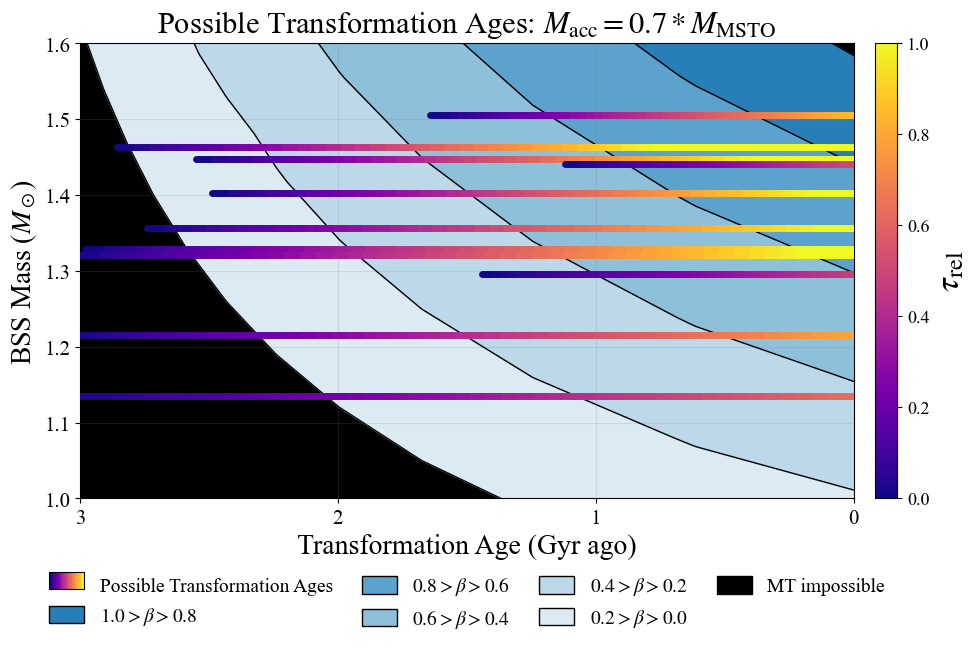

In [154]:
from pathlib import Path
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Patch, Rectangle
from matplotlib.legend_handler import HandlerBase


# using serif font throughout the figure
plt.rcParams.update({"font.family": "serif","font.serif": ["Times New Roman","Times","Nimbus Roman","DejaVu Serif"], "mathtext.fontset": "stix", "axes.unicode_minus": False})

# legend used to show the plasma colormap as small gradient rectangle in legend
class ColormapLegend: pass

class HandlerColormap(HandlerBase):
    def __init__(self,cmap,number_of_stripes=20,**kwargs):
        super().__init__(**kwargs)
        self.cmap = cmap
        self.number_of_stripes = number_of_stripes

    def create_artists(self,legend,original_handle,xdescent,ydescent,width,height,fontsize,transform):
        artists = []
        stripe_width = (width/ self.number_of_stripes)
        for stripe_index in range(self.number_of_stripes):
            color_fraction = (stripe_index/ (self.number_of_stripes- 1))
            stripe = Rectangle((xdescent+ stripe_index* stripe_width,ydescent),stripe_width,height,transform=transform,facecolor=self.cmap(color_fraction),edgecolor="none")
            artists.append(stripe)

        # black border around the gradient key
        border = Rectangle((xdescent,ydescent),width,height,transform=transform,facecolor="none",edgecolor="black",linewidth=0.8)
        artists.append(border)
        return artists


#  ------------------------------ 1. NGC 2243 BSS measurements ------------------------------

gaia_ids = np.array([
    "2893941099963718528",
    "2893941890237671936",
    "2893942062036322688",
    "2893942714871393280",
    "2893942749231117568",
    "2893942783590846080",
    "2893946150845192192",
    "2893946563162115712",
    "2893948212429455360",
    "2893942062036323200",
    "2893941821518204544"
])

bss_masses = np.array([
    1.4024817527559055,
    1.505140587519026,
    1.3293698808373593,
    1.1346207708894878,
    1.447423462295082,
    1.4413425958904111,
    1.3565244705882353,
    1.2155096389548694,
    1.2961819145077722,
    1.4628821288888887,
    1.321006404040404
])

base9_log_ages = np.array([
    9.398882984,
    9.219416015999998,
    9.476608947999999,
    9.496683639999999,
    9.40911139,
    9.05523444,
    9.440790621,
    9.490731845,
    9.163875699,
    9.458466942,
    9.485075804000001
])

if not (len(gaia_ids)== len(bss_masses)== len(base9_log_ages)):
    raise ValueError("The Gaia ID, BSS mass, and BASE-9 age arrays ""must all contain the same number of stars.")

# convert log10(age / yr) to Gyr
base9_ages_gyr = (10**base9_log_ages/ 1.0e9)

print("Number of BSSs:",len(bss_masses))

#  ------------------------------ 2. reading in MIST track files ------------------------------

# exact names of the MIST .track.eep files
track_filenames = {1.0: "0010000M.track.eep",1.1: "0011000M.track.eep",1.2: "0012000M.track.eep",1.3: "0013000M.track.eep",1.4: "0014000M.track.eep",1.5: "0015000M.track.eep",1.6: "0016000M.track.eep",1.7: "0017000M.track.eep",1.8: "0018000M.track.eep",1.9: "0019000M.track.eep", 2.0: "0020000M.track.eep",2.1: "0021000M.track.eep",2.2: "0022000M.track.eep",2.3: "0023000M.track.eep",2.4: "0024000M.track.eep",2.5: "0025000M.track.eep",2.6: "0026000M.track.eep",2.7: "0027000M.track.eep",2.8: "0028000M.track.eep", 2.9: "0029000M.track.eep",3.0: "0030000M.track.eep"}

#  ------------------------------ 3. locating track directory ------------------------------

# looking for files in same folder as notebook
possible_track_directories = [Path.cwd(),Path("/mnt/data"),Path(cluster_path + "MIST_eep_6a84877d11cce/")]

def locate_exact_file(filename):
    """
    Locate one exact filename in the notebook directory
    or in /mnt/data.
    """

    for directory in possible_track_directories:
        filepath = (directory / filename)
        if filepath.exists():
            return filepath
    raise FileNotFoundError(
        f"Could not find '{filename}'.\n" "Place the MIST files in the same folder as the notebook " "or update possible_track_directories.")

#  ------------------------------ 4. reading one MIST .track.eep file ------------------------------

def read_mist_eep_track(filepath,initial_mass):
    """
    Read one MIST .track.eep file.

    Returns the model columns needed for the
    mass-transfer contour calculation.
    """

    filepath = Path(filepath)

    # the MIST .track.eep files contain 11 header lines
    # the next line contains the actual model column names!
    data = np.genfromtxt(filepath,skip_header=11,names=True,dtype=None,encoding=None)

    if data.size == 0:raise ValueError(f"No model rows were read from {filepath.name}.")

    column_names = list(data.dtype.names)

    required_columns = [ "star_age", "star_mass", "he_core_mass", "c_core_mass", "phase"]

    missing_columns = [column
        for column in required_columns
        if column not in column_names]

    if missing_columns:
        raise KeyError(f"{filepath.name} is missing required columns: "+ ", ".join(missing_columns))
    return {"filepath": filepath,"initial_mass": float(initial_mass),"data": data,"column_names": column_names,"star_age": np.asarray(data["star_age"],dtype=float),"star_mass": np.asarray(data["star_mass"],dtype=float),"he_core_mass": np.asarray(data["he_core_mass"],dtype=float),"c_core_mass": np.asarray(data["c_core_mass"],dtype=float),"phase": np.asarray(data["phase"],dtype=float)}

#  ------------------------------ 5. reading all 21 MIST evolutionary tracks ------------------------------

mist_tracks = {}

print()
print("Reading MIST evolutionary tracks")
print("------------------------------------------------------------")

for initial_mass, filename in track_filenames.items():
    filepath = locate_exact_file(filename)
    track = read_mist_eep_track(filepath,initial_mass)
    mist_tracks[initial_mass] = track
    print(f"{initial_mass:3.1f} M_sun   "f"{filepath.name}")

if len(mist_tracks) != len(track_filenames):
    raise ValueError("Not all requested MIST tracks were successfully read.")

available_track_masses = np.array(sorted(mist_tracks.keys()),dtype=float)

print()
print(f"Successfully read {len(mist_tracks)} ""MIST evolutionary tracks.")

print("Available initial masses:", available_track_masses)

#  ------------------------------ 6. checking available evolutionary phases ------------------------------

# MIST phasees:
#   -1 = pre-main sequence
#    0 = main sequence
#    2 = subgiant branch & red giant branch
#    3 = core-helium burning
#    4 = early AGB
#    5 = thermally pulsing AGB
#    6 = post-AGB

print()
print("MIST phase coverage")
print("------------------------------------------------------------")
print("Mass       phases present       " "EAGB?     TPAGB?    first TPAGB age")
print("(Msun)                                          (Gyr)")
print("------------------------------------------------------------")

for mass in available_track_masses:
    track = mist_tracks[mass]
    phase = track["phase"]
    phase_values = np.unique(phase)
    has_eagb = np.any(np.isclose(phase,4.0))
    tpagb_indices = np.where(np.isclose(phase,5.0))[0]
    has_tpagb = (len(tpagb_indices) > 0)

    if has_tpagb:
        first_tpagb_index = (tpagb_indices[0])
        first_tpagb_age_gyr = (track["star_age"][first_tpagb_index] / 1.0e9)
        age_text = (f"{first_tpagb_age_gyr:.4f}")
    else:
        age_text = "---"
    print(f"{mass:4.1f}       "f"{str(phase_values):21s}   "f"{str(has_eagb):5s}     "f"{str(has_tpagb):5s}       "f"{age_text}")


#  ------------------------------ 7. building MIST lookup tables for the contours ------------------------------

# current age of cluster
cluster_age_now_gyr = 3.6

# arrays for the MSTO mass lookup table
    # absolute TAMS ages are used to determine what mass reaches MSTO at a given cluster age
tams_ages_gyr = []
msto_initial_masses = []

# separate arrays for BSS MS lifetimes
    # MIST primary EEP definitions are used: 
        # EEP 202 = ZAMS
        # EEP 454 = TAMS

# tau_MS calculated as: tau_MS = age(EEP 454) - age(EEP 202)
track_initial_masses = []
track_zams_ages_gyr = []
track_tams_ages_gyr = []
track_main_sequence_lifetimes_gyr = []

# arrays for AGB donor and WD mass lookup table
agb_initial_masses = []
tpagb_ages_gyr = []
agb_masses = []
wd_masses = []
envelope_masses = []

for initial_mass in available_track_masses:
    track = mist_tracks[initial_mass]
    phase = track["phase"]
    star_age = track["star_age"]
    star_mass = track["star_mass"]

    # ---------- identifying the ZAMS and TAMS using MIST EEP numbers ----------

    # MIST documentation: EEP number = zero-based Python array index + 1
        # EEP 202 -> Python index 201
        # EEP 454 -> Python index 453
    zams_eep_number = 202
    tams_eep_number = 454
    zams_index = (zams_eep_number - 1)
    tams_index = (tams_eep_number - 1)

    # making sure this track has both required EEPs
    if len(star_age) <= tams_index:
        raise ValueError(f"{initial_mass:.1f} M_sun track does not contain "f"the required TAMS EEP {tams_eep_number}.")

    # stellar age at the MIST-defined ZAMS
    zams_age_gyr = (star_age[zams_index] / 1.0e9)

    # stellar age at the MIST-defined TAMS
    tams_age_gyr = (star_age[tams_index] / 1.0e9)

    # total MS lifetime
        # tau_MS = age at TAMS - age at ZAMS
    main_sequence_lifetime_gyr = (tams_age_gyr - zams_age_gyr)

    if (not np.isfinite(main_sequence_lifetime_gyr)or main_sequence_lifetime_gyr <= 0):
        raise ValueError(f"Invalid EEP-based main-sequence lifetime for "f"{initial_mass:.1f} M_sun track.")

    # absolute TAMS age used for MSTO interpolation
    tams_ages_gyr.append(tams_age_gyr)

    msto_initial_masses.append(initial_mass)

    # ZAMS-to-TAMS duration used for BSS relative ages
    track_initial_masses.append(initial_mass)

    track_zams_ages_gyr.append(zams_age_gyr)

    track_tams_ages_gyr.append(tams_age_gyr)

    track_main_sequence_lifetimes_gyr.append(main_sequence_lifetime_gyr)

    # ---------- finding the beginning of the TP-AGB ----------

    tpagb_indices = np.where(np.isclose(phase,5.0))[0]

    # finding final post-AGB model point
    post_agb_indices = np.where(np.isclose(phase,6.0))[0]

    if (len(tpagb_indices) == 0
        or len(post_agb_indices) == 0):
        continue

    first_tpagb_index = (tpagb_indices[0])

    final_post_agb_index = (post_agb_indices[-1])

    # age when this donor reaches the TP-AGB
    tpagb_age_gyr = (star_age[first_tpagb_index] / 1.0e9)

    # current stellar mass at the beginning of the TP-AGB
    M_AGB = star_mass[first_tpagb_index]

    # final stellar mass at the end of the post-AGB track
    M_WD = star_mass[final_post_agb_index]

    # material available in the AGB envelope
    M_envelope = (M_AGB - M_WD)

    if not np.isfinite(M_envelope):
        continue

    if M_envelope <= 0:
        print(f"Warning: non-positive envelope mass for "f"{initial_mass:.1f} M_sun track.")
        continue

    # saving the initial track mass with all other quantities before sorting by TP-AGB age
    agb_initial_masses.append(initial_mass)

    tpagb_ages_gyr.append(tpagb_age_gyr)

    agb_masses.append(M_AGB)

    wd_masses.append(M_WD)

    envelope_masses.append(M_envelope)

# converting all lists into NumPy arrays
tams_ages_gyr = np.asarray(tams_ages_gyr, dtype=float)
msto_initial_masses = np.asarray(msto_initial_masses, dtype=float)
track_initial_masses = np.asarray(track_initial_masses, dtype=float)
track_zams_ages_gyr = np.asarray(track_zams_ages_gyr, dtype=float)
track_tams_ages_gyr = np.asarray(track_tams_ages_gyr, dtype=float)
track_main_sequence_lifetimes_gyr = np.asarray(track_main_sequence_lifetimes_gyr, dtype=float)
agb_initial_masses = np.asarray(agb_initial_masses, dtype=float)
tpagb_ages_gyr = np.asarray(tpagb_ages_gyr, dtype=float)
agb_masses = np.asarray(agb_masses, dtype=float)
wd_masses = np.asarray(wd_masses, dtype=float)
envelope_masses = np.asarray(envelope_masses, dtype=float)

if len(tams_ages_gyr) < 2:
    raise ValueError("Not enough tracks contain main-sequence points to construct the MSTO interpolation.")

if len(track_main_sequence_lifetimes_gyr) < 2:
    raise ValueError("Not enough tracks contain valid ZAMS and TAMS points to construct the BSS lifetime interpolation.")

if len(tpagb_ages_gyr) < 2:
    raise ValueError("Not enough tracks contain TP-AGB and post-AGB points to construct the donor interpolation.")

# sorting MSTO table by absolute TAMS age 
msto_order = np.argsort(tams_ages_gyr)
tams_ages_gyr = tams_ages_gyr[msto_order]
msto_initial_masses = msto_initial_masses[msto_order]

# sorting BSS MS lifetime table by mass 
lifetime_order = np.argsort(track_initial_masses)
track_initial_masses = track_initial_masses[lifetime_order]
track_zams_ages_gyr = track_zams_ages_gyr[lifetime_order]
track_tams_ages_gyr = track_tams_ages_gyr[lifetime_order]
track_main_sequence_lifetimes_gyr = track_main_sequence_lifetimes_gyr[lifetime_order]

# checking that the measured BSS masses are covered by the MIST lifetime mass grid
if np.min(bss_masses) < np.min(track_initial_masses) or np.max(bss_masses) > np.max(track_initial_masses):
    raise ValueError("One or more BSS masses fall outside the mass range covered by the MIST main-sequence tracks.")

# interpolating MIST-defined quantities for each measured BSS mass
bss_zams_ages_gyr = np.interp(bss_masses, track_initial_masses, track_zams_ages_gyr)
bss_tams_ages_gyr = np.interp(bss_masses, track_initial_masses, track_tams_ages_gyr)
bss_main_sequence_lifetimes_gyr = np.interp(bss_masses, track_initial_masses, track_main_sequence_lifetimes_gyr)

# relative age reached at the BASE-9 upper limit
bss_current_relative_ages = (base9_ages_gyr - bss_zams_ages_gyr) / bss_main_sequence_lifetimes_gyr

print()
print("MIST main-sequence lifetime lookup table")
print("----------------------------------------------------------------")
print("Initial mass    ZAMS age    TAMS age    MS lifetime")
print("   (Msun)         (Gyr)       (Gyr)         (Gyr)")
print("----------------------------------------------------------------")

for initial_mass, zams_age, tams_age, lifetime in zip(track_initial_masses, track_zams_ages_gyr, track_tams_ages_gyr, track_main_sequence_lifetimes_gyr):
    print(f"{initial_mass:7.2f}       {zams_age:7.4f}     {tams_age:7.4f}       {lifetime:7.4f}")
print()
print("BSS main-sequence lifetime and relative-age check")
print("--------------------------------------------------------------------------")
print("Gaia source ID          BSS mass    BASE-9 age    tau_MS     tau_rel,current")
print("                         (Msun)        (Gyr)       (Gyr)")
print("--------------------------------------------------------------------------")

for gaia_id, mass, age, lifetime, current_relative_age in zip(gaia_ids, bss_masses, base9_ages_gyr, bss_main_sequence_lifetimes_gyr, bss_current_relative_ages):
    print(f"{gaia_id}    {mass:7.4f}       {age:7.4f}      {lifetime:7.4f}      {current_relative_age:7.4f}")

# warning if BASE-9 ages and MIST lifetimes produce endpoint relative ages outside the physical 0 to 1 range
if np.any(bss_current_relative_ages > 1.0):
    print()
    print("Warning: one or more BASE-9 age upper limits produce tau_rel > 1 when divided by the MIST ZAMS-to-TAMS lifetime.")
    print("Those bar colors will be clipped at tau_rel = 1. This may reflect differences between the BASE-9 and MIST stellar-model age estimates.")

# sorting all AGB quantities by TP-AGB age
agb_order = np.argsort(tpagb_ages_gyr)
agb_initial_masses = agb_initial_masses[agb_order]
tpagb_ages_gyr = tpagb_ages_gyr[agb_order]
agb_masses = agb_masses[agb_order]
wd_masses = wd_masses[agb_order]
envelope_masses = envelope_masses[agb_order]

# printing the correctly matched lookup table
print()
print("MIST TP-AGB donor lookup table")
print("-------------------------------------------------------------")
print("Initial    TP-AGB age    M_AGB      M_WD      M_envelope")
print(" mass         Gyr        Msun       Msun         Msun")
print("-------------------------------------------------------------")

for initial_mass, agb_age, M_AGB, M_WD, M_env in zip(agb_initial_masses, tpagb_ages_gyr, agb_masses, wd_masses, envelope_masses):
    print(f"{initial_mass:5.2f}       {agb_age:7.4f}     {M_AGB:7.4f}    {M_WD:7.4f}      {M_env:7.4f}")

#  ------------------------------ 8. calculating five mass-transfer contours ------------------------------

# transformation ages shown on the plot
contour_transformation_ages = np.linspace(0.0, 3.0, 300)

# age when each transformation occurred
cluster_age_then_gyr = cluster_age_now_gyr - contour_transformation_ages

# contours can only be calculated where both the MSTO and TP-AGB tables cover the cluster age!
minimum_model_age = max(np.min(tams_ages_gyr), np.min(tpagb_ages_gyr))
maximum_model_age = min(np.max(tams_ages_gyr), np.max(tpagb_ages_gyr))
valid_contour_ages = (cluster_age_then_gyr >= minimum_model_age) & (cluster_age_then_gyr <= maximum_model_age)

if not np.any(valid_contour_ages):
    raise ValueError("The MIST tracks do not cover the requested transformation-age range.")

# interpolating MSTO, TP-AGB donor, and WD masses at each cluster age
M_MSTO_contour = np.full_like(contour_transformation_ages, np.nan)
M_AGB_contour = np.full_like(contour_transformation_ages, np.nan)
M_WD_contour = np.full_like(contour_transformation_ages, np.nan)

M_MSTO_contour[valid_contour_ages] = np.interp(cluster_age_then_gyr[valid_contour_ages], tams_ages_gyr, msto_initial_masses)
M_AGB_contour[valid_contour_ages] = np.interp(cluster_age_then_gyr[valid_contour_ages], tpagb_ages_gyr, agb_masses)
M_WD_contour[valid_contour_ages] = np.interp(cluster_age_then_gyr[valid_contour_ages], tpagb_ages_gyr, wd_masses)

# available donor envelope
M_envelope_contour = M_AGB_contour - M_WD_contour

# left-panel assumption: accretor initially has the MSTO mass
M_accretor_contour = 0.7*M_MSTO_contour

# mass transfer efficiencies
beta_values = np.array([0.2, 0.4, 0.6, 0.8, 1.0])

# final BSS mass: M_BSS = M_accretor + beta * M_envelope
contour_bss_masses = {}
for beta in beta_values:
    contour_bss_masses[beta] = M_accretor_contour + beta * M_envelope_contour


# printing the model-supported age range
print()
print(f"Model-supported cluster-age range: {minimum_model_age:.4f} to {maximum_model_age:.4f} Gyr")
print(f"Model-supported transformation-age range: {cluster_age_now_gyr - maximum_model_age:.4f} to {cluster_age_now_gyr - minimum_model_age:.4f} Gyr ago")


# printing contour values at selected transformation ages
print()
print("Interpolated contour-model check")
print("--------------------------------------------------------------------------")
print("t_trans   cluster age   M_MSTO   M_AGB   M_WD   M_envelope   M_BSS(beta=1)")
print("  Gyr         Gyr        Msun    Msun    Msun       Msun           Msun")
print("--------------------------------------------------------------------------")

for requested_age in [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    index = np.argmin(np.abs(contour_transformation_ages - requested_age))

    if not valid_contour_ages[index]:
        print(f"{requested_age:6.2f}   outside model coverage")
        continue

    print(f"{contour_transformation_ages[index]:6.2f}   {cluster_age_then_gyr[index]:9.4f}   {M_MSTO_contour[index]:6.3f}   {M_AGB_contour[index]:6.3f}   {M_WD_contour[index]:6.3f}      {M_envelope_contour[index]:6.3f}         {contour_bss_masses[1.0][index]:6.3f}")

#  ------------------------------ 9. plot settings ------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

minimum_bss_mass = 1.0
maximum_bss_mass = 1.6

# only using transformation ages supported by both model lookup tables
valid_transformation_ages = contour_transformation_ages[valid_contour_ages]
valid_M_accretor = M_accretor_contour[valid_contour_ages]
valid_beta_02 = contour_bss_masses[0.2][valid_contour_ages]
valid_beta_04 = contour_bss_masses[0.4][valid_contour_ages]
valid_beta_06 = contour_bss_masses[0.6][valid_contour_ages]
valid_beta_08 = contour_bss_masses[0.8][valid_contour_ages]
valid_beta_10 = contour_bss_masses[1.0][valid_contour_ages]


#  ------------------------------ 10. adding filled beta contour regions ------------------------------

# plotting region black first
    # represents a BSS mass that can't be produced using an efficiency between beta = 0 & beta = 1
ax.fill_between(valid_transformation_ages, minimum_bss_mass, maximum_bss_mass, color="black", zorder=0)

# contours stop slightly before 2.0 Gyr, so the unsupported interval is filled in black
ax.fill_between([np.max(valid_transformation_ages), 3.0], minimum_bss_mass, maximum_bss_mass, color="black", zorder=0)

# lighter blue = lower required efficiency & darker blue = higher required efficiency
beta_color_00_02 = "#dceaf4"
beta_color_02_04 = "#bdd8e8"
beta_color_04_06 = "#8fc0d9"
beta_color_06_08 = "#5ba2cc"
beta_color_08_10 = "#287fb8"

ax.fill_between(valid_transformation_ages, valid_M_accretor, valid_beta_02, color=beta_color_00_02, zorder=1)
ax.fill_between(valid_transformation_ages, valid_beta_02, valid_beta_04, color=beta_color_02_04, zorder=1)
ax.fill_between(valid_transformation_ages, valid_beta_04, valid_beta_06, color=beta_color_04_06, zorder=1)
ax.fill_between(valid_transformation_ages, valid_beta_06, valid_beta_08, color=beta_color_06_08, zorder=1)
ax.fill_between(valid_transformation_ages, valid_beta_08, valid_beta_10, color=beta_color_08_10, zorder=1)

#  ------------------------------ 11. adding beta contour boundary lines ------------------------------

# beta = 0 corresponds to no transferred envelope material
ax.plot(valid_transformation_ages, valid_M_accretor, color="black", linewidth=1.0, zorder=2)

# plot boundaries for beta = 0.2, 0.4, 0.6, 0.8, and 1.0
for beta in beta_values:
    ax.plot(valid_transformation_ages, contour_bss_masses[beta][valid_contour_ages], color="black", linewidth=1.0, zorder=2)

#  ------------------------------ 12. horizontal bar relative-age colormap settings ------------------------------

# horizontal segments & colorbar represent relative MS age at transformation:
    # t_evol,trans = t_BASE9 - t_trans
    # tau_rel = (t_evol,trans - t_ZAMS) / (t_TAMS - t_ZAMS)
        # or tau_rel = (t_BASE9 - t_trans - t_ZAMS) / tau_MS, where tau_MS = t_TAMS - t_ZAMS
    # tau_rel = 0 corresponds to MIST ZAMS
    # tau_rel = 1 corresponds to MIST TAMS

cmap = plt.cm.plasma
relative_age_norm = Normalize(vmin=0.0, vmax=1.0, clip=True)

# number of points used for each horizontal bar
number_of_points = 51

#  ------------------------------ 13. making one relative-age gradient bar per BSS ------------------------------

for mass, age_limit, zams_age, main_sequence_lifetime in zip(bss_masses, base9_ages_gyr, bss_zams_ages_gyr, bss_main_sequence_lifetimes_gyr):

    # oldest physically allowed transformation age - inferred BSS evolution age reaches the MIST ZAMS
    maximum_transformation_age = age_limit - zams_age

    if maximum_transformation_age <= 0.0:
        continue

    # displayed x-axis only extends to 2 Gyr
    displayed_limit = min(maximum_transformation_age, 3.0)

    # transformation-age positions are the x-coordinates
    transformation_ages = np.linspace(0.0, displayed_limit, number_of_points)

    # every point in the bar has same BSS mass
    mass_values = np.full(number_of_points, mass)

    # combining x & y coordinates and connecting neighboring pairs
    points = np.column_stack([transformation_ages, mass_values])
    segments = np.stack([points[:-1], points[1:]], axis=1)

    # transformation age at the midpoint of each segment
    segment_transformation_ages = 0.5 * (transformation_ages[:-1] + transformation_ages[1:])

    # evolution age of the BSS at each possible transformation time
        # from Linck & Mathieu (2026): evolution age at transformation = current evolution age - transformation age
    segment_evolution_ages = age_limit - segment_transformation_ages

    # relative MS age at transformation
    segment_relative_ages = (segment_evolution_ages - zams_age) / main_sequence_lifetime

    line_collection = LineCollection(segments, array=segment_relative_ages, cmap=cmap, norm=relative_age_norm, linewidths=5, capstyle="round", zorder=4)
    ax.add_collection(line_collection)

#  ------------------------------ 14. adding legend below the plot ------------------------------

# test object represented by plasma-gradient rectangle
transformation_age_handle = ColormapLegend()

beta_legend_handles = [transformation_age_handle,Patch(facecolor=beta_color_08_10, edgecolor="black", label=r"$1.0 > \beta > 0.8$"),Patch(facecolor=beta_color_06_08, edgecolor="black", label=r"$0.8 > \beta > 0.6$"),Patch(facecolor=beta_color_04_06, edgecolor="black", label=r"$0.6 > \beta > 0.4$"),Patch(facecolor=beta_color_02_04, edgecolor="black", label=r"$0.4 > \beta > 0.2$"), Patch(facecolor=beta_color_00_02, edgecolor="black", label=r"$0.2 > \beta > 0.0$"),Patch(facecolor="black", edgecolor="black", label="MT impossible")]

beta_legend_labels = ["Possible Transformation Ages",r"$1.0 > \beta > 0.8$",r"$0.8 > \beta > 0.6$",r"$0.6 > \beta > 0.4$",r"$0.4 > \beta > 0.2$",r"$0.2 > \beta > 0.0$","MT impossible"]

# negative y-value places legend directly below x-axis
ax.legend(handles=beta_legend_handles,labels=beta_legend_labels,handler_map={ColormapLegend: HandlerColormap(cmap)},loc="upper center",bbox_to_anchor=(0.5, -0.15),ncol=4,fontsize=14,frameon=False,handlelength=1.8,handleheight=1.0,columnspacing=1.5,borderaxespad=0.0)

#  ------------------------------ 15. formatting axes like in figure 4 of Linck & Mathieu (2026) ------------------------------

ax.set_xlim(0.0, 3.0)
ax.set_ylim(minimum_bss_mass, maximum_bss_mass)

# figure 4 puts older transformations on the left and present day at 0 Gyr on the right
ax.invert_xaxis()

ax.set_xticks([0.0, 1.0, 2.0, 3.0])
ax.set_xlabel("Transformation Age (Gyr ago)", fontsize=20)
ax.set_ylabel(r"BSS Mass ($M_\odot$)", fontsize=20)
ax.set_title(r"Possible Transformation Ages: $M_{\rm acc}=0.7*M_{\rm MSTO}$", fontsize=22, pad=8)

ax.tick_params(axis="both", which="major", labelsize=15)
ax.grid(alpha=0.18, color="gray", zorder=3)

#  ------------------------------ 16. adding relative-age colorbar on the right of plot ------------------------------

# colorbar uses the same plasma colormap and relative-age normalization as horizontal BSS bars
colorbar_mappable = plt.cm.ScalarMappable(cmap=cmap, norm=relative_age_norm)
colorbar_mappable.set_array([])

cbar = fig.colorbar(colorbar_mappable, ax=ax, pad=0.025, fraction=0.050)
cbar.set_ticks(np.arange(0.0, 1.01, 0.2))
cbar.set_label(r"$\tau_{\rm rel}$", fontsize=25)
cbar.ax.tick_params(labelsize=13)

# applying serif font to colorbar tick labels
for tick_label in cbar.ax.get_yticklabels():
    tick_label.set_fontfamily("serif")

#  ------------------------------ 17. printing plotted limits for verification ------------------------------

print()
print("Gaia source ID          BSS mass    BASE-9 upper limit    tau_MS    tau_rel,current")
print("                         (Msun)             (Gyr)          (Gyr)")
print("----------------------------------------------------------------------------")

for gaia_id, mass, age_limit, lifetime, relative_age_limit in zip(gaia_ids, bss_masses, base9_ages_gyr, bss_main_sequence_lifetimes_gyr, bss_current_relative_ages):
    print(f"{gaia_id}    {mass:7.4f}          {age_limit:7.4f}         {lifetime:7.4f}      {relative_age_limit:7.4f}")

#  ------------------------------ 18. layout, save, and display ------------------------------

# saving space on the right for the vertical colorbar and below the axes for the two-row legend
fig.subplots_adjust(left=0.11, right=0.87, top=0.89, bottom=0.24)

fig.savefig(cluster_path + 'plots/' + cluster_name + "_beta_contours.png", dpi=300, bbox_inches="tight")

plt.show()

### $M_{acc}$ contours for fixed $\beta$

Choose an efficiency to check:

In [227]:
beta = 0.3

Number of BSSs: 11

Reading MIST evolutionary tracks
------------------------------------------------------------
1.0 M_sun   0010000M.track.eep
1.1 M_sun   0011000M.track.eep
1.2 M_sun   0012000M.track.eep
1.3 M_sun   0013000M.track.eep
1.4 M_sun   0014000M.track.eep
1.5 M_sun   0015000M.track.eep
1.6 M_sun   0016000M.track.eep
1.7 M_sun   0017000M.track.eep
1.8 M_sun   0018000M.track.eep
1.9 M_sun   0019000M.track.eep
2.0 M_sun   0020000M.track.eep
2.1 M_sun   0021000M.track.eep
2.2 M_sun   0022000M.track.eep
2.3 M_sun   0023000M.track.eep
2.4 M_sun   0024000M.track.eep
2.5 M_sun   0025000M.track.eep
2.6 M_sun   0026000M.track.eep
2.7 M_sun   0027000M.track.eep
2.8 M_sun   0028000M.track.eep
2.9 M_sun   0029000M.track.eep
3.0 M_sun   0030000M.track.eep

Successfully read 21 MIST evolutionary tracks.
Available initial masses: [1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7
 2.8 2.9 3. ]

MIST phase coverage
-----------------------------------------------------

/var/folders/5b/q81xz4jn4vzdvcxbxc8cv4dr0000gn/T/ipykernel_51913/3003828460.py:580: UserWarning: Mismatched number of handles and labels: len(handles) = 7 len(labels) = 8
  ax.legend(handles=beta_legend_handles,labels=beta_legend_labels,handler_map={ColormapLegend: HandlerColormap(cmap)},loc="upper center",bbox_to_anchor=(0.5, -0.15),ncol=4,fontsize=14,frameon=False,handlelength=1.8,handleheight=1.0,columnspacing=1.5,borderaxespad=0.0)


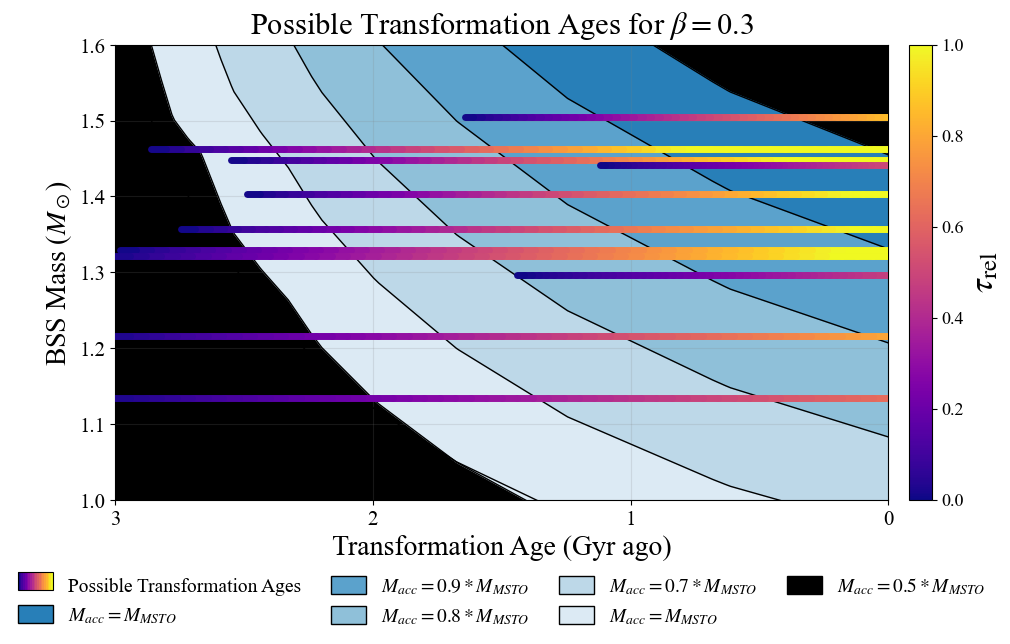

In [229]:
from pathlib import Path
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Patch, Rectangle
from matplotlib.legend_handler import HandlerBase



# using serif font throughout the figure
plt.rcParams.update({"font.family": "serif","font.serif": ["Times New Roman","Times","Nimbus Roman","DejaVu Serif"], "mathtext.fontset": "stix", "axes.unicode_minus": False})

# legend used to show the plasma colormap as small gradient rectangle in legend
class ColormapLegend: pass

class HandlerColormap(HandlerBase):
    def __init__(self,cmap,number_of_stripes=20,**kwargs):
        super().__init__(**kwargs)
        self.cmap = cmap
        self.number_of_stripes = number_of_stripes

    def create_artists(self,legend,original_handle,xdescent,ydescent,width,height,fontsize,transform):
        artists = []
        stripe_width = (width/ self.number_of_stripes)
        for stripe_index in range(self.number_of_stripes):
            color_fraction = (stripe_index/ (self.number_of_stripes- 1))
            stripe = Rectangle((xdescent+ stripe_index* stripe_width,ydescent),stripe_width,height,transform=transform,facecolor=self.cmap(color_fraction),edgecolor="none")
            artists.append(stripe)

        # black border around the gradient key
        border = Rectangle((xdescent,ydescent),width,height,transform=transform,facecolor="none",edgecolor="black",linewidth=0.8)
        artists.append(border)
        return artists


#  ------------------------------ 1. Measurements ------------------------------

gaia_ids = np.array([
    "2893941099963718528",
    "2893941890237671936",
    "2893942062036322688",
    "2893942714871393280",
    "2893942749231117568",
    "2893942783590846080",
    "2893946150845192192",
    "2893946563162115712",
    "2893948212429455360",
    "2893942062036323200",
    "2893941821518204544"
])

bss_masses = np.array([
    1.4024817527559055,
    1.505140587519026,
    1.3293698808373593,
    1.1346207708894878,
    1.447423462295082,
    1.4413425958904111,
    1.3565244705882353,
    1.2155096389548694,
    1.2961819145077722,
    1.4628821288888887,
    1.321006404040404
])

base9_log_ages = np.array([
    9.398882984,
    9.219416015999998,
    9.476608947999999,
    9.496683639999999,
    9.40911139,
    9.05523444,
    9.440790621,
    9.490731845,
    9.163875699,
    9.458466942,
    9.485075804000001
])

if not (len(gaia_ids)== len(bss_masses)== len(base9_log_ages)):
    raise ValueError("The Gaia ID, BSS mass, and BASE-9 age arrays ""must all contain the same number of stars.")

# convert log10(age / yr) to Gyr
base9_ages_gyr = (10**base9_log_ages/ 1.0e9)

print("Number of BSSs:",len(bss_masses))

#  ------------------------------ 2. reading in MIST track files ------------------------------

# exact names of the MIST .track.eep files
track_filenames = {1.0: "0010000M.track.eep",1.1: "0011000M.track.eep",1.2: "0012000M.track.eep",1.3: "0013000M.track.eep",1.4: "0014000M.track.eep",1.5: "0015000M.track.eep",1.6: "0016000M.track.eep",1.7: "0017000M.track.eep",1.8: "0018000M.track.eep",1.9: "0019000M.track.eep", 2.0: "0020000M.track.eep",2.1: "0021000M.track.eep",2.2: "0022000M.track.eep",2.3: "0023000M.track.eep",2.4: "0024000M.track.eep",2.5: "0025000M.track.eep",2.6: "0026000M.track.eep",2.7: "0027000M.track.eep",2.8: "0028000M.track.eep", 2.9: "0029000M.track.eep",3.0: "0030000M.track.eep"}

#  ------------------------------ 3. locating track directory ------------------------------

# looking for files in same folder as notebook
possible_track_directories = [Path.cwd(),Path("/mnt/data"),Path(cluster_path + "MIST_eep_6a84877d11cce/")]

def locate_exact_file(filename):
    """
    Locate one exact filename in the notebook directory
    or in /mnt/data.
    """

    for directory in possible_track_directories:
        filepath = (directory / filename)
        if filepath.exists():
            return filepath
    raise FileNotFoundError(
        f"Could not find '{filename}'.\n" "Place the MIST files in the same folder as the notebook " "or update possible_track_directories.")

#  ------------------------------ 4. reading one MIST .track.eep file ------------------------------

def read_mist_eep_track(filepath,initial_mass):
    """
    Read one MIST .track.eep file.

    Returns the model columns needed for the
    mass-transfer contour calculation.
    """

    filepath = Path(filepath)

    # the MIST .track.eep files contain 11 header lines
    # the next line contains the actual model column names!
    data = np.genfromtxt(filepath,skip_header=11,names=True,dtype=None,encoding=None)

    if data.size == 0:raise ValueError(f"No model rows were read from {filepath.name}.")

    column_names = list(data.dtype.names)

    required_columns = [ "star_age", "star_mass", "he_core_mass", "c_core_mass", "phase"]

    missing_columns = [column
        for column in required_columns
        if column not in column_names]

    if missing_columns:
        raise KeyError(f"{filepath.name} is missing required columns: "+ ", ".join(missing_columns))
    return {"filepath": filepath,"initial_mass": float(initial_mass),"data": data,"column_names": column_names,"star_age": np.asarray(data["star_age"],dtype=float),"star_mass": np.asarray(data["star_mass"],dtype=float),"he_core_mass": np.asarray(data["he_core_mass"],dtype=float),"c_core_mass": np.asarray(data["c_core_mass"],dtype=float),"phase": np.asarray(data["phase"],dtype=float)}

#  ------------------------------ 5. reading all 21 MIST evolutionary tracks ------------------------------

mist_tracks = {}

print()
print("Reading MIST evolutionary tracks")
print("------------------------------------------------------------")

for initial_mass, filename in track_filenames.items():
    filepath = locate_exact_file(filename)
    track = read_mist_eep_track(filepath,initial_mass)
    mist_tracks[initial_mass] = track
    print(f"{initial_mass:3.1f} M_sun   "f"{filepath.name}")

if len(mist_tracks) != len(track_filenames):
    raise ValueError("Not all requested MIST tracks were successfully read.")

available_track_masses = np.array(sorted(mist_tracks.keys()),dtype=float)

print()
print(f"Successfully read {len(mist_tracks)} ""MIST evolutionary tracks.")

print("Available initial masses:", available_track_masses)

#  ------------------------------ 6. checking available evolutionary phases ------------------------------

# MIST phasees:
#   -1 = pre-main sequence
#    0 = main sequence
#    2 = subgiant branch & red giant branch
#    3 = core-helium burning
#    4 = early AGB
#    5 = thermally pulsing AGB
#    6 = post-AGB

print()
print("MIST phase coverage")
print("------------------------------------------------------------")
print("Mass       phases present       " "EAGB?     TPAGB?    first TPAGB age")
print("(Msun)                                          (Gyr)")
print("------------------------------------------------------------")

for mass in available_track_masses:
    track = mist_tracks[mass]
    phase = track["phase"]
    phase_values = np.unique(phase)
    has_eagb = np.any(np.isclose(phase,4.0))
    tpagb_indices = np.where(np.isclose(phase,5.0))[0]
    has_tpagb = (len(tpagb_indices) > 0)

    if has_tpagb:
        first_tpagb_index = (tpagb_indices[0])
        first_tpagb_age_gyr = (track["star_age"][first_tpagb_index] / 1.0e9)
        age_text = (f"{first_tpagb_age_gyr:.4f}")
    else:
        age_text = "---"
    print(f"{mass:4.1f}       "f"{str(phase_values):21s}   "f"{str(has_eagb):5s}     "f"{str(has_tpagb):5s}       "f"{age_text}")


#  ------------------------------ 7. building MIST lookup tables for the contours ------------------------------

#########
# current age of cluster - CHANGE
cluster_age_now_gyr = 3.6
#########


# arrays for the MSTO mass lookup table
    # absolute TAMS ages are used to determine what mass reaches MSTO at a given cluster age
tams_ages_gyr = []
msto_initial_masses = []

# separate arrays for BSS MS lifetimes
    # MIST primary EEP definitions are used: 
        # EEP 202 = ZAMS
        # EEP 454 = TAMS

# tau_MS calculated as: tau_MS = age(EEP 454) - age(EEP 202)
track_initial_masses = []
track_zams_ages_gyr = []
track_tams_ages_gyr = []
track_main_sequence_lifetimes_gyr = []

# arrays for AGB donor and WD mass lookup table
agb_initial_masses = []
tpagb_ages_gyr = []
agb_masses = []
wd_masses = []
envelope_masses = []

for initial_mass in available_track_masses:
    track = mist_tracks[initial_mass]
    phase = track["phase"]
    star_age = track["star_age"]
    star_mass = track["star_mass"]

    # ---------- identifying the ZAMS and TAMS using MIST EEP numbers ----------

    # MIST documentation: EEP number = zero-based Python array index + 1
        # EEP 202 -> Python index 201
        # EEP 454 -> Python index 453
    zams_eep_number = 202
    tams_eep_number = 454
    zams_index = (zams_eep_number - 1)
    tams_index = (tams_eep_number - 1)

    # making sure this track has both required EEPs
    if len(star_age) <= tams_index:
        raise ValueError(f"{initial_mass:.1f} M_sun track does not contain "f"the required TAMS EEP {tams_eep_number}.")

    # stellar age at the MIST-defined ZAMS
    zams_age_gyr = (star_age[zams_index] / 1.0e9)

    # stellar age at the MIST-defined TAMS
    tams_age_gyr = (star_age[tams_index] / 1.0e9)

    # total MS lifetime
        # tau_MS = age at TAMS - age at ZAMS
    main_sequence_lifetime_gyr = (tams_age_gyr - zams_age_gyr)

    if (not np.isfinite(main_sequence_lifetime_gyr)or main_sequence_lifetime_gyr <= 0):
        raise ValueError(f"Invalid EEP-based main-sequence lifetime for "f"{initial_mass:.1f} M_sun track.")

    # absolute TAMS age used for MSTO interpolation
    tams_ages_gyr.append(tams_age_gyr)

    msto_initial_masses.append(initial_mass)

    # ZAMS-to-TAMS duration used for BSS relative ages
    track_initial_masses.append(initial_mass)

    track_zams_ages_gyr.append(zams_age_gyr)

    track_tams_ages_gyr.append(tams_age_gyr)

    track_main_sequence_lifetimes_gyr.append(main_sequence_lifetime_gyr)

    # ---------- finding the beginning of the TP-AGB ----------

    tpagb_indices = np.where(np.isclose(phase,5.0))[0]

    # finding final post-AGB model point
    post_agb_indices = np.where(np.isclose(phase,6.0))[0]

    if (len(tpagb_indices) == 0
        or len(post_agb_indices) == 0):
        continue

    first_tpagb_index = (tpagb_indices[0])

    final_post_agb_index = (post_agb_indices[-1])

    # age when this donor reaches the TP-AGB
    tpagb_age_gyr = (star_age[first_tpagb_index] / 1.0e9)

    # current stellar mass at the beginning of the TP-AGB
    M_AGB = star_mass[first_tpagb_index]

    # final stellar mass at the end of the post-AGB track
    M_WD = star_mass[final_post_agb_index]

    # material available in the AGB envelope
    M_envelope = (M_AGB - M_WD)

    if not np.isfinite(M_envelope):
        continue

    if M_envelope <= 0:
        print(f"Warning: non-positive envelope mass for "f"{initial_mass:.1f} M_sun track.")
        continue

    # saving the initial track mass with all other quantities before sorting by TP-AGB age
    agb_initial_masses.append(initial_mass)

    tpagb_ages_gyr.append(tpagb_age_gyr)

    agb_masses.append(M_AGB)

    wd_masses.append(M_WD)

    envelope_masses.append(M_envelope)

# converting all lists into NumPy arrays
tams_ages_gyr = np.asarray(tams_ages_gyr, dtype=float)
msto_initial_masses = np.asarray(msto_initial_masses, dtype=float)
track_initial_masses = np.asarray(track_initial_masses, dtype=float)
track_zams_ages_gyr = np.asarray(track_zams_ages_gyr, dtype=float)
track_tams_ages_gyr = np.asarray(track_tams_ages_gyr, dtype=float)
track_main_sequence_lifetimes_gyr = np.asarray(track_main_sequence_lifetimes_gyr, dtype=float)
agb_initial_masses = np.asarray(agb_initial_masses, dtype=float)
tpagb_ages_gyr = np.asarray(tpagb_ages_gyr, dtype=float)
agb_masses = np.asarray(agb_masses, dtype=float)
wd_masses = np.asarray(wd_masses, dtype=float)
envelope_masses = np.asarray(envelope_masses, dtype=float)

if len(tams_ages_gyr) < 2:
    raise ValueError("Not enough tracks contain main-sequence points to construct the MSTO interpolation.")

if len(track_main_sequence_lifetimes_gyr) < 2:
    raise ValueError("Not enough tracks contain valid ZAMS and TAMS points to construct the BSS lifetime interpolation.")

if len(tpagb_ages_gyr) < 2:
    raise ValueError("Not enough tracks contain TP-AGB and post-AGB points to construct the donor interpolation.")

# sorting MSTO table by absolute TAMS age 
msto_order = np.argsort(tams_ages_gyr)
tams_ages_gyr = tams_ages_gyr[msto_order]
msto_initial_masses = msto_initial_masses[msto_order]

# sorting BSS MS lifetime table by mass 
lifetime_order = np.argsort(track_initial_masses)
track_initial_masses = track_initial_masses[lifetime_order]
track_zams_ages_gyr = track_zams_ages_gyr[lifetime_order]
track_tams_ages_gyr = track_tams_ages_gyr[lifetime_order]
track_main_sequence_lifetimes_gyr = track_main_sequence_lifetimes_gyr[lifetime_order]

# checking that the measured BSS masses are covered by the MIST lifetime mass grid
if np.min(bss_masses) < np.min(track_initial_masses) or np.max(bss_masses) > np.max(track_initial_masses):
    raise ValueError("One or more BSS masses fall outside the mass range covered by the MIST main-sequence tracks.")

# interpolating MIST-defined quantities for each measured BSS mass
bss_zams_ages_gyr = np.interp(bss_masses, track_initial_masses, track_zams_ages_gyr)
bss_tams_ages_gyr = np.interp(bss_masses, track_initial_masses, track_tams_ages_gyr)
bss_main_sequence_lifetimes_gyr = np.interp(bss_masses, track_initial_masses, track_main_sequence_lifetimes_gyr)

# relative age reached at the BASE-9 upper limit
bss_current_relative_ages = (base9_ages_gyr - bss_zams_ages_gyr) / bss_main_sequence_lifetimes_gyr

print()
print("MIST main-sequence lifetime lookup table")
print("----------------------------------------------------------------")
print("Initial mass    ZAMS age    TAMS age    MS lifetime")
print("   (Msun)         (Gyr)       (Gyr)         (Gyr)")
print("----------------------------------------------------------------")

for initial_mass, zams_age, tams_age, lifetime in zip(track_initial_masses, track_zams_ages_gyr, track_tams_ages_gyr, track_main_sequence_lifetimes_gyr):
    print(f"{initial_mass:7.2f}       {zams_age:7.4f}     {tams_age:7.4f}       {lifetime:7.4f}")
print()
print("BSS main-sequence lifetime and relative-age check")
print("--------------------------------------------------------------------------")
print("Gaia source ID          BSS mass    BASE-9 age    tau_MS     tau_rel,current")
print("                         (Msun)        (Gyr)       (Gyr)")
print("--------------------------------------------------------------------------")

for gaia_id, mass, age, lifetime, current_relative_age in zip(gaia_ids, bss_masses, base9_ages_gyr, bss_main_sequence_lifetimes_gyr, bss_current_relative_ages):
    print(f"{gaia_id}    {mass:7.4f}       {age:7.4f}      {lifetime:7.4f}      {current_relative_age:7.4f}")

# warning if BASE-9 ages and MIST lifetimes produce endpoint relative ages outside the physical 0 to 1 range
if np.any(bss_current_relative_ages > 1.0):
    print()
    print("Warning: one or more BASE-9 age upper limits produce tau_rel > 1 when divided by the MIST ZAMS-to-TAMS lifetime.")
    print("Those bar colors will be clipped at tau_rel = 1. This may reflect differences between the BASE-9 and MIST stellar-model age estimates.")

# sorting all AGB quantities by TP-AGB age
agb_order = np.argsort(tpagb_ages_gyr)
agb_initial_masses = agb_initial_masses[agb_order]
tpagb_ages_gyr = tpagb_ages_gyr[agb_order]
agb_masses = agb_masses[agb_order]
wd_masses = wd_masses[agb_order]
envelope_masses = envelope_masses[agb_order]

# printing the correctly matched lookup table
print()
print("MIST TP-AGB donor lookup table")
print("-------------------------------------------------------------")
print("Initial    TP-AGB age    M_AGB      M_WD      M_envelope")
print(" mass         Gyr        Msun       Msun         Msun")
print("-------------------------------------------------------------")

for initial_mass, agb_age, M_AGB, M_WD, M_env in zip(agb_initial_masses, tpagb_ages_gyr, agb_masses, wd_masses, envelope_masses):
    print(f"{initial_mass:5.2f}       {agb_age:7.4f}     {M_AGB:7.4f}    {M_WD:7.4f}      {M_env:7.4f}")

#  ------------------------------ 8. calculating five mass-transfer contours ------------------------------

# transformation ages shown on the plot
contour_transformation_ages = np.linspace(0.0, 3.0, 300)

# age when each transformation occurred
cluster_age_then_gyr = cluster_age_now_gyr - contour_transformation_ages

# contours can only be calculated where both the MSTO and TP-AGB tables cover the cluster age!
minimum_model_age = max(np.min(tams_ages_gyr), np.min(tpagb_ages_gyr))
maximum_model_age = min(np.max(tams_ages_gyr), np.max(tpagb_ages_gyr))
valid_contour_ages = (cluster_age_then_gyr >= minimum_model_age) & (cluster_age_then_gyr <= maximum_model_age)

if not np.any(valid_contour_ages):
    raise ValueError("The MIST tracks do not cover the requested transformation-age range.")

# interpolating MSTO, TP-AGB donor, and WD masses at each cluster age
M_MSTO_contour = np.full_like(contour_transformation_ages, np.nan)
M_AGB_contour = np.full_like(contour_transformation_ages, np.nan)
M_WD_contour = np.full_like(contour_transformation_ages, np.nan)

M_MSTO_contour[valid_contour_ages] = np.interp(cluster_age_then_gyr[valid_contour_ages], tams_ages_gyr, msto_initial_masses)
M_AGB_contour[valid_contour_ages] = np.interp(cluster_age_then_gyr[valid_contour_ages], tpagb_ages_gyr, agb_masses)
M_WD_contour[valid_contour_ages] = np.interp(cluster_age_then_gyr[valid_contour_ages], tpagb_ages_gyr, wd_masses)

# available donor envelope
M_envelope_contour = M_AGB_contour - M_WD_contour

# M_accretors to check
macc_values = np.array([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])

# final BSS mass: M_BSS = M_accretor + beta * M_envelope
contour_bss_masses = {}
for macc in macc_values:
    contour_bss_masses[macc] = macc*M_MSTO_contour + beta * M_envelope_contour

# printing the model-supported age range
print()
print(f"Model-supported cluster-age range: {minimum_model_age:.4f} to {maximum_model_age:.4f} Gyr")
print(f"Model-supported transformation-age range: {cluster_age_now_gyr - maximum_model_age:.4f} to {cluster_age_now_gyr - minimum_model_age:.4f} Gyr ago")


# printing contour values at selected transformation ages
print()
print("Interpolated contour-model check")
print("--------------------------------------------------------------------------")
print("t_trans   cluster age   M_MSTO   M_AGB   M_WD   M_envelope   M_BSS(beta=1)")
print("  Gyr         Gyr        Msun    Msun    Msun       Msun           Msun")
print("--------------------------------------------------------------------------")

for requested_age in [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    index = np.argmin(np.abs(contour_transformation_ages - requested_age))

    if not valid_contour_ages[index]:
        print(f"{requested_age:6.2f}   outside model coverage")
        continue

    print(f"{contour_transformation_ages[index]:6.2f}   {cluster_age_then_gyr[index]:9.4f}   {M_MSTO_contour[index]:6.3f}   {M_AGB_contour[index]:6.3f}   {M_WD_contour[index]:6.3f}      {M_envelope_contour[index]:6.3f}         {contour_bss_masses[1.0][index]:6.3f}")

#  ------------------------------ 9. plot settings ------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

minimum_bss_mass = 1.0
maximum_bss_mass = 1.6

# only using transformation ages supported by both model lookup tables
valid_transformation_ages = contour_transformation_ages[valid_contour_ages]
valid_macc_05 = contour_bss_masses[0.5][valid_contour_ages]
valid_macc_06 = contour_bss_masses[0.6][valid_contour_ages]
valid_macc_07 = contour_bss_masses[0.7][valid_contour_ages]
valid_macc_08 = contour_bss_masses[0.8][valid_contour_ages]
valid_macc_09 = contour_bss_masses[0.9][valid_contour_ages]
valid_macc_10 = contour_bss_masses[1.0][valid_contour_ages]


#  ------------------------------ 10. adding filled beta contour regions ------------------------------

# plotting region black first
    # represents a BSS mass that can't be produced using an efficiency between beta = 0 & beta = 1
ax.fill_between(valid_transformation_ages, minimum_bss_mass, maximum_bss_mass, color="black", zorder=0)

# contours stop slightly before 2.0 Gyr, so the unsupported interval is filled in black
ax.fill_between([np.max(valid_transformation_ages), 3.0], minimum_bss_mass, maximum_bss_mass, color="black", zorder=0)

# lighter blue = lower required efficiency & darker blue = higher required efficiency
beta_color_00_02 = "#dceaf4"
beta_color_02_04 = "#bdd8e8"
beta_color_04_06 = "#8fc0d9"
beta_color_06_08 = "#5ba2cc"
beta_color_08_10 = "#287fb8"

ax.fill_between(valid_transformation_ages, valid_macc_05, valid_macc_06, color=beta_color_00_02, zorder=1)
ax.fill_between(valid_transformation_ages, valid_macc_06, valid_macc_07, color=beta_color_02_04, zorder=1)
ax.fill_between(valid_transformation_ages, valid_macc_07, valid_macc_08, color=beta_color_04_06, zorder=1)
ax.fill_between(valid_transformation_ages, valid_macc_08, valid_macc_09, color=beta_color_06_08, zorder=1)
ax.fill_between(valid_transformation_ages, valid_macc_09, valid_macc_10, color=beta_color_08_10, zorder=1)

#  ------------------------------ 11. adding beta contour boundary lines ------------------------------

# beta = 0 corresponds to no transferred envelope material
ax.plot(valid_transformation_ages, valid_M_accretor, color="black", linewidth=1.0, zorder=2)

# plot boundaries 
for macc in macc_values:
    ax.plot(valid_transformation_ages, contour_bss_masses[macc][valid_contour_ages], color="black", linewidth=1.0, zorder=2)

#  ------------------------------ 12. horizontal bar relative-age colormap settings ------------------------------

# horizontal segments & colorbar represent relative MS age at transformation:
    # t_evol,trans = t_BASE9 - t_trans
    # tau_rel = (t_evol,trans - t_ZAMS) / (t_TAMS - t_ZAMS)
        # or tau_rel = (t_BASE9 - t_trans - t_ZAMS) / tau_MS, where tau_MS = t_TAMS - t_ZAMS
    # tau_rel = 0 corresponds to MIST ZAMS
    # tau_rel = 1 corresponds to MIST TAMS

cmap = plt.cm.plasma
relative_age_norm = Normalize(vmin=0.0, vmax=1.0, clip=True)

# number of points used for each horizontal bar
number_of_points = 51

#  ------------------------------ 13. making one relative-age gradient bar per BSS ------------------------------

for mass, age_limit, zams_age, main_sequence_lifetime in zip(bss_masses, base9_ages_gyr, bss_zams_ages_gyr, bss_main_sequence_lifetimes_gyr):

    # oldest physically allowed transformation age - inferred BSS evolution age reaches the MIST ZAMS
    maximum_transformation_age = age_limit - zams_age

    if maximum_transformation_age <= 0.0:
        continue

    # displayed x-axis only extends to 2 Gyr
    displayed_limit = min(maximum_transformation_age, 3.0)

    # transformation-age positions are the x-coordinates
    transformation_ages = np.linspace(0.0, displayed_limit, number_of_points)

    # every point in the bar has same BSS mass
    mass_values = np.full(number_of_points, mass)

    # combining x & y coordinates and connecting neighboring pairs
    points = np.column_stack([transformation_ages, mass_values])
    segments = np.stack([points[:-1], points[1:]], axis=1)

    # transformation age at the midpoint of each segment
    segment_transformation_ages = 0.5 * (transformation_ages[:-1] + transformation_ages[1:])

    # evolution age of the BSS at each possible transformation time
        # from Linck & Mathieu (2026): evolution age at transformation = current evolution age - transformation age
    segment_evolution_ages = age_limit - segment_transformation_ages

    # relative MS age at transformation
    segment_relative_ages = (segment_evolution_ages - zams_age) / main_sequence_lifetime

    line_collection = LineCollection(segments, array=segment_relative_ages, cmap=cmap, norm=relative_age_norm, linewidths=5, capstyle="round", zorder=4)
    ax.add_collection(line_collection)

#  ------------------------------ 14. adding legend below the plot ------------------------------

# test object represented by plasma-gradient rectangle
transformation_age_handle = ColormapLegend()

beta_legend_handles = [transformation_age_handle,Patch(facecolor=beta_color_08_10, edgecolor="black", label=r"$1.0 > \beta > 0.8$"),Patch(facecolor=beta_color_06_08, edgecolor="black", label=r"$0.8 > \beta > 0.6$"),Patch(facecolor=beta_color_04_06, edgecolor="black", label=r"$0.6 > \beta > 0.4$"),Patch(facecolor=beta_color_02_04, edgecolor="black", label=r"$0.4 > \beta > 0.2$"), Patch(facecolor=beta_color_00_02, edgecolor="black", label=r"$0.2 > \beta > 0.0$"),Patch(facecolor="black", edgecolor="black", label="MT impossible")]

beta_legend_labels = ["Possible Transformation Ages",r"$M_{acc} = M_{MSTO}$",r"$M_{acc} = 0.9*M_{MSTO}$",r"$M_{acc} = 0.8*M_{MSTO}$",r"$M_{acc} = 0.7*M_{MSTO}$",r"$M_{acc} = M_{MSTO}$",r"$M_{acc} = 0.5*M_{MSTO}$","MT impossible"]

# negative y-value places legend directly below x-axis
ax.legend(handles=beta_legend_handles,labels=beta_legend_labels,handler_map={ColormapLegend: HandlerColormap(cmap)},loc="upper center",bbox_to_anchor=(0.5, -0.15),ncol=4,fontsize=14,frameon=False,handlelength=1.8,handleheight=1.0,columnspacing=1.5,borderaxespad=0.0)

#  ------------------------------ 15. formatting axes like in figure 4 of Linck & Mathieu (2026) ------------------------------

ax.set_xlim(0.0, 3.0)
ax.set_ylim(minimum_bss_mass, maximum_bss_mass)

# figure 4 puts older transformations on the left and present day at 0 Gyr on the right
ax.invert_xaxis()

ax.set_xticks([0.0, 1.0, 2.0, 3.0])
ax.set_xlabel("Transformation Age (Gyr ago)", fontsize=20)
ax.set_ylabel(r"BSS Mass ($M_\odot$)", fontsize=20)
ax.set_title(r"Possible Transformation Ages for $\beta = $" + str(beta), fontsize=22, pad=8)

ax.tick_params(axis="both", which="major", labelsize=15)
ax.grid(alpha=0.18, color="gray", zorder=3)

#  ------------------------------ 16. adding relative-age colorbar on the right of plot ------------------------------

# colorbar uses the same plasma colormap and relative-age normalization as horizontal BSS bars
colorbar_mappable = plt.cm.ScalarMappable(cmap=cmap, norm=relative_age_norm)
colorbar_mappable.set_array([])

cbar = fig.colorbar(colorbar_mappable, ax=ax, pad=0.025, fraction=0.050)
cbar.set_ticks(np.arange(0.0, 1.01, 0.2))
cbar.set_label(r"$\tau_{\rm rel}$", fontsize=25)
cbar.ax.tick_params(labelsize=13)

# applying serif font to colorbar tick labels
for tick_label in cbar.ax.get_yticklabels():
    tick_label.set_fontfamily("serif")

#  ------------------------------ 17. printing plotted limits for verification ------------------------------

print()
print("Gaia source ID          BSS mass    BASE-9 upper limit    tau_MS    tau_rel,current")
print("                         (Msun)             (Gyr)          (Gyr)")
print("----------------------------------------------------------------------------")

for gaia_id, mass, age_limit, lifetime, relative_age_limit in zip(gaia_ids, bss_masses, base9_ages_gyr, bss_main_sequence_lifetimes_gyr, bss_current_relative_ages):
    print(f"{gaia_id}    {mass:7.4f}          {age_limit:7.4f}         {lifetime:7.4f}      {relative_age_limit:7.4f}")

#  ------------------------------ 18. layout, save, and display ------------------------------

# saving space on the right for the vertical colorbar and below the axes for the two-row legend
fig.subplots_adjust(left=0.11, right=0.87, top=0.89, bottom=0.24)

fig.savefig(cluster_path + 'plots/transformation_Macc_contours/' + cluster_name + "_Macc_contours_beta" + str(beta) + ".png", dpi=300, bbox_inches="tight")

plt.show()